In [ ]:
!pip -q install kagglehub tensorflow scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import os, glob, json, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    balanced_accuracy_score, roc_curve, precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
sns.set_theme(style="whitegrid")

TensorFlow: 2.21.0
GPU devices: []


In [ ]:
DATASET_HANDLES = {
    "Heart": "fedesoriano/heart-failure-prediction",
    "Diabetes": "iammustafatz/diabetes-prediction-dataset",
    "Parkinsons": "vikasukani/parkinsons-disease-data-set",
    "Kidney": "mansoordaku/ckdisease",
    "Liver": "uciml/indian-liver-patient-records"
}

DATA_DIR = Path("/content/healthguard_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

dataset_dirs = {}
for disease, handle in DATASET_HANDLES.items():
    print(f"Downloading {disease} dataset...")
    try:
        downloaded_path = kagglehub.dataset_download(handle)
        dataset_dirs[disease] = Path(downloaded_path)
        print("Saved at:", downloaded_path)
    except Exception as e:
        print(f"Download failed for {disease}: {e}")
        print("Check internet access, Kaggle dataset availability, and authentication.")

print("Downloaded datasets:", list(dataset_dirs.keys()))

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.
Saved at: /kaggle/input/heart-failure-prediction
Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Saved at: /kaggle/input/diabetes-prediction-dataset
Using Colab cache for faster access to the 'parkinsons-disease-data-set' dataset.
Saved at: /kaggle/input/parkinsons-disease-data-set
Using Colab cache for faster access to the 'ckdisease' dataset.
Saved at: /kaggle/input/ckdisease
Using Colab cache for faster access to the 'indian-liver-patient-records' dataset.
Saved at: /kaggle/input/indian-liver-patient-records
Downloaded datasets: ['Heart', 'Diabetes', 'Parkinsons', 'Kidney', 'Liver']


In [ ]:
def find_csv_files(folder):
    return sorted(Path(folder).rglob("*.csv"))

csv_files = {}
for disease, folder in dataset_dirs.items():
    files = find_csv_files(folder)
    csv_files[disease] = files
    print(f"\\n{disease}:")
    for f in files:
        print(" -", f)

def preview_csv(disease):
    files = csv_files.get(disease, [])
    if not files:
        print("No CSV file found for", disease)
        return
    for f in files[:3]:
        try:
            temp = pd.read_csv(f)
            print("\\nFILE:", f.name, "| shape:", temp.shape)
            display(temp.head(3))
            print("Columns:", list(temp.columns))
        except Exception as e:
            print("Could not read", f, e)

for disease in csv_files:
    preview_csv(disease)

\nHeart:
 - /kaggle/input/heart-failure-prediction/heart.csv
\nDiabetes:
 - /kaggle/input/diabetes-prediction-dataset/diabetes_prediction_dataset.csv
\nParkinsons:
\nKidney:
 - /kaggle/input/ckdisease/kidney_disease.csv
\nLiver:
 - /kaggle/input/indian-liver-patient-records/indian_liver_patient.csv
\nFILE: heart.csv | shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0


Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']
\nFILE: diabetes_prediction_dataset.csv | shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0


Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']
No CSV file found for Parkinsons
\nFILE: kidney_disease.csv | shape: (400, 26)


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.02,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.02,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.01,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd


Columns: ['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']
\nFILE: indian_liver_patient.csv | shape: (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1


Columns: ['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio', 'Dataset']


In [ ]:
TARGET_CANDIDATES = {
    "Heart": ["HeartDisease", "heartdisease", "target", "output"],
    "Diabetes": ["diabetes", "Diabetes", "Outcome", "outcome"],
    "Parkinsons": ["status", "Status", "target"],
    "Kidney": ["classification", "classification.", "Class", "class"],
    "Liver": ["Dataset", "dataset", "Selector", "target"]
}

def choose_csv(files):
    if not files:
        raise FileNotFoundError("No CSV file found.")
    # Prefer the largest CSV; many Kaggle datasets contain tiny metadata CSVs.
    scored = []
    for f in files:
        try:
            scored.append((f.stat().st_size, f))
        except Exception:
            pass
    return max(scored, key=lambda x: x[0])[1] if scored else files[0]

def find_target_column(df, candidates):
    lower_map = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.strip().lower() in lower_map:
            return lower_map[candidate.strip().lower()]
    # Fallback: last column, but it must have a small number of unique values.
    last = df.columns[-1]
    if df[last].nunique(dropna=True) <= 10:
        print("WARNING: using fallback target column:", last)
        return last
    raise ValueError("Could not safely identify target column. Inspect columns and edit TARGET_CANDIDATES.")

raw_datasets = {}
target_columns = {}

for disease, files in csv_files.items():
    if not files:
        continue
    chosen = choose_csv(files)
    df = pd.read_csv(chosen)
    target = find_target_column(df, TARGET_CANDIDATES[disease])
    raw_datasets[disease] = df
    target_columns[disease] = target
    print(f"\\n{disease}: file={chosen.name}, target={target}, shape={df.shape}")
    print(df[target].value_counts(dropna=False).head(10))

\nHeart: file=heart.csv, target=HeartDisease, shape=(918, 12)
HeartDisease
1    508
0    410
Name: count, dtype: int64
\nDiabetes: file=diabetes_prediction_dataset.csv, target=diabetes, shape=(100000, 9)
diabetes
0    91500
1     8500
Name: count, dtype: int64
\nKidney: file=kidney_disease.csv, target=classification, shape=(400, 26)
classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64
\nLiver: file=indian_liver_patient.csv, target=Dataset, shape=(583, 11)
Dataset
1    416
2    167
Name: count, dtype: int64


In [ ]:
def encode_binary_target(series):
    s = series.astype(str).str.strip().str.lower()
    s = s.replace({"?": np.nan, "nan": np.nan, "none": np.nan, "": np.nan})
    valid = s.dropna()
    unique = list(pd.unique(valid))
    if len(unique) != 2:
        raise ValueError(f"Expected exactly 2 target classes, found {unique}")

    positive_words = {"1", "yes", "true", "positive", "ckd", "present", "disease"}
    negative_words = {"0", "no", "false", "negative", "notckd", "absent", "no disease"}

    mapping = {}
    for value in unique:
        if value in positive_words:
            mapping[value] = 1
        elif value in negative_words:
            mapping[value] = 0

    if len(mapping) != 2:
        # Deterministic fallback; verify this mapping against dataset documentation.
        ordered = sorted(unique)
        mapping = {ordered[0]: 0, ordered[1]: 1}
        print("WARNING: verify target meaning for mapping:", mapping)
    return s.map(mapping).astype("float"), mapping

prepared = {}
for disease, df_original in raw_datasets.items():
    df = df_original.copy()
    target_col = target_columns[disease]
    y, label_mapping = encode_binary_target(df[target_col])
    df = df.loc[y.notna()].copy()
    y = y.loc[df.index].astype(int)

    X = df.drop(columns=[target_col])
    # Drop likely row identifiers, not clinically meaningful measurements.
    id_cols = [c for c in X.columns if str(c).strip().lower() in
               {"id", "patientid", "patient_id", "name", "record_id"}]
    X = X.drop(columns=id_cols, errors="ignore")

    # Replace common missing-value markers.
    X = X.replace(["?", " ?", "NA", "N/A", "na", "null", ""], np.nan)
    # Convert numeric-looking text columns to numeric where possible.
    for col in X.columns:
        converted = pd.to_numeric(X[col], errors="coerce")
        if converted.notna().mean() >= 0.70:
            X[col] = converted

    X = pd.get_dummies(X, drop_first=False)
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.loc[:, X.nunique(dropna=False) > 1]

    if X.shape[1] == 0:
        raise ValueError(f"No usable features remained for {disease}.")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=SEED, stratify=y
    )

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_train_imp = imputer.fit_transform(X_train)
    X_test_imp = imputer.transform(X_test)

    X_train_scaled = scaler.fit_transform(X_train_imp).astype("float32")
    X_test_scaled = scaler.transform(X_test_imp).astype("float32")

    prepared[disease] = {
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
        "y_train": y_train.to_numpy().astype("int32"),
        "y_test": y_test.to_numpy().astype("int32"),
        "feature_names": list(X.columns),
        "imputer": imputer,
        "scaler": scaler,
        "label_mapping": label_mapping,
        "original_columns": list(X.columns)
    }

    print(f"\\n{disease}: features={X.shape[1]}, train={len(y_train)}, test={len(y_test)}")
    print("Label mapping:", label_mapping)
    print("Train classes:", np.bincount(y_train))
    print("Test classes:", np.bincount(y_test))

\nHeart: features=20, train=734, test=184
Label mapping: {'0': 0, '1': 1}
Train classes: [328 406]
Test classes: [ 82 102]
\nDiabetes: features=15, train=80000, test=20000
Label mapping: {'0': 0, '1': 1}
Train classes: [73200  6800]
Test classes: [18300  1700]
\nKidney: features=86, train=320, test=80
Label mapping: {'ckd': 1, 'notckd': 0}
Train classes: [120 200]
Test classes: [30 50]
\nLiver: features=11, train=466, test=117
Label mapping: {'1': 0, '2': 1}
Train classes: [333 133]
Test classes: [83 34]


,Disease,Training rows,Testing rows,Features,Positive rate (train)
0,Heart,734,184,20,0.553134
1,Diabetes,80000,20000,15,0.085000
2,Kidney,320,80,86,0.625000
3,Liver,466,117,11,0.285408


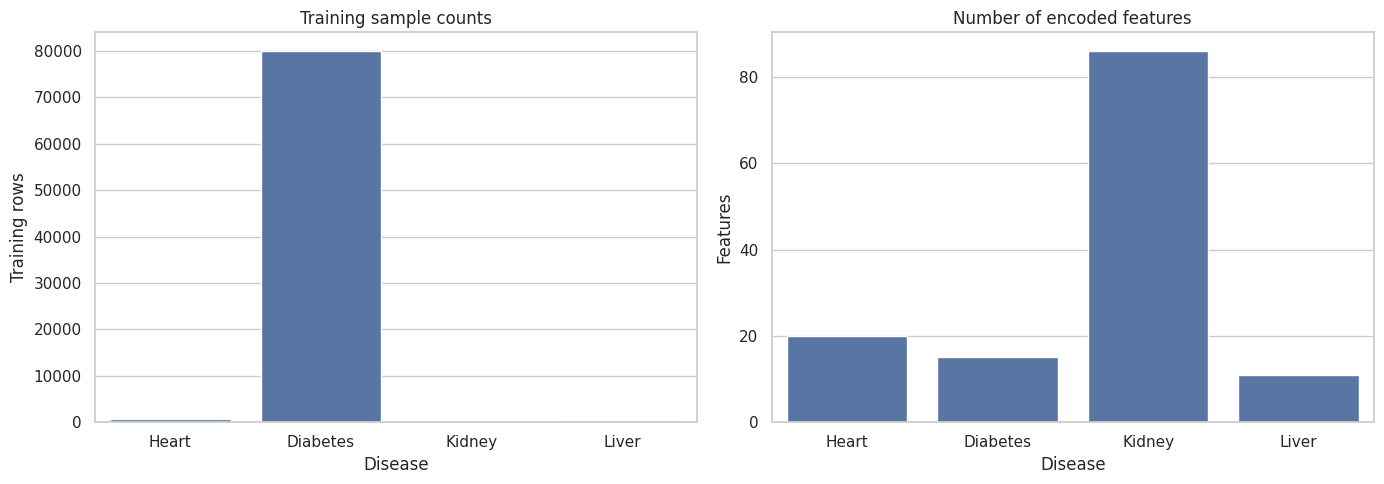

In [ ]:
profile_rows = []
for disease, item in prepared.items():
    profile_rows.append({
        "Disease": disease,
        "Training rows": len(item["y_train"]),
        "Testing rows": len(item["y_test"]),
        "Features": item["X_train"].shape[1],
        "Positive rate (train)": float(item["y_train"].mean())
    })
profile_df = pd.DataFrame(profile_rows)
display(profile_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=profile_df, x="Disease", y="Training rows", ax=axes[0])
axes[0].set_title("Training sample counts")
sns.barplot(data=profile_df, x="Disease", y="Features", ax=axes[1])
axes[1].set_title("Number of encoded features")
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=12, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6
        )
    ]

def build_dnn(input_dim):
    inputs = keras.Input(shape=(input_dim,), name="patient_features")
    x = layers.Dense(128, activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.20)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="risk_probability")(x)
    model = keras.Model(inputs, outputs, name="HealthGuard_DNN")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall")
        ]
    )
    return model

print("DNN architecture function ready.")

DNN architecture function ready.


In [ ]:
dnn_models, dnn_histories = {}, {}
all_results = []

def evaluate_binary(y_true, probabilities):
    probabilities = np.asarray(probabilities).ravel()
    predictions = (probabilities >= 0.5).astype(int)
    cm = confusion_matrix(y_true, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities) if len(np.unique(y_true)) == 2 else np.nan
    }

for disease, item in prepared.items():
    print(f"\\nTraining DNN for {disease}...")
    model = build_dnn(item["X_train"].shape[1])
    classes = np.unique(item["y_train"])
    weights = compute_class_weight(
        class_weight="balanced", classes=classes, y=item["y_train"]
    )
    class_weights = {int(c): float(w) for c, w in zip(classes, weights)}

    history = model.fit(
        item["X_train"], item["y_train"],
        validation_split=0.20,
        epochs=100,
        batch_size=32,
        callbacks=make_callbacks(),
        class_weight=class_weights,
        verbose=0
    )
    probs = model.predict(item["X_test"], verbose=0).ravel()
    metrics = evaluate_binary(item["y_test"], probs)

    dnn_models[disease] = model
    dnn_histories[disease] = history
    all_results.append({"Disease": disease, "Model": "DNN", **metrics})
    print(metrics)

print("\\nDNN training completed for:", list(dnn_models.keys()))

\nTraining DNN for Heart...
{'Accuracy': 0.8967391304347826, 'Balanced Accuracy': np.float64(0.8949067431850789), 'Precision': 0.9029126213592233, 'Recall': 0.9117647058823529, 'Specificity': np.float64(0.8780487804878049), 'F1': 0.9073170731707317, 'ROC_AUC': np.float64(0.9473935915829746)}
\nTraining DNN for Diabetes...
{'Accuracy': 0.9018, 'Balanced Accuracy': np.float64(0.9081870781099325), 'Precision': 0.46092362344582594, 'Recall': 0.9158823529411765, 'Specificity': np.float64(0.9004918032786885), 'F1': 0.6132335565183143, 'ROC_AUC': np.float64(0.9756537929926069)}
\nTraining DNN for Kidney...
{'Accuracy': 0.95, 'Balanced Accuracy': np.float64(0.96), 'Precision': 1.0, 'Recall': 0.92, 'Specificity': np.float64(1.0), 'F1': 0.9583333333333334, 'ROC_AUC': np.float64(0.9993333333333333)}
\nTraining DNN for Liver...
{'Accuracy': 0.6153846153846154, 'Balanced Accuracy': np.float64(0.6334160170092134), 'Precision': 0.40350877192982454, 'Recall': 0.6764705882352942, 'Specificity': np.floa

In [ ]:
def build_attention_dnn(input_dim):
    inputs = keras.Input(shape=(input_dim,), name="patient_features")
    attention = layers.Dense(
        input_dim, activation="softmax", name="feature_attention"
    )(inputs)
    attended = layers.Multiply()([inputs, attention])
    x = layers.Dense(128, activation="relu")(attended)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Dense(32, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name="HealthGuard_Attention_DNN")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0005),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall")
        ]
    )
    return model

attention_models, attention_histories = {}, {}
for disease, item in prepared.items():
    print(f"Training Attention DNN for {disease}...")
    model = build_attention_dnn(item["X_train"].shape[1])
    classes = np.unique(item["y_train"])
    weights = compute_class_weight("balanced", classes=classes, y=item["y_train"])
    cw = {int(c): float(w) for c, w in zip(classes, weights)}
    history = model.fit(
        item["X_train"], item["y_train"],
        validation_split=0.20, epochs=100, batch_size=32,
        callbacks=make_callbacks(), class_weight=cw, verbose=0
    )
    probs = model.predict(item["X_test"], verbose=0).ravel()
    metrics = evaluate_binary(item["y_test"], probs)
    attention_models[disease] = model
    attention_histories[disease] = history
    all_results.append({"Disease": disease, "Model": "Attention DNN", **metrics})
    print(metrics)

Training Attention DNN for Heart...
{'Accuracy': 0.8695652173913043, 'Balanced Accuracy': np.float64(0.8680057388809181), 'Precision': 0.8823529411764706, 'Recall': 0.8823529411764706, 'Specificity': np.float64(0.8536585365853658), 'F1': 0.8823529411764706, 'ROC_AUC': np.float64(0.9139167862266858)}
Training Attention DNN for Diabetes...
{'Accuracy': 0.91255, 'Balanced Accuracy': np.float64(0.906057537769206), 'Precision': 0.49210441508217856, 'Recall': 0.898235294117647, 'Specificity': np.float64(0.913879781420765), 'F1': 0.6358525921299188, 'ROC_AUC': np.float64(0.9770132272581162)}
Training Attention DNN for Kidney...
{'Accuracy': 1.0, 'Balanced Accuracy': np.float64(1.0), 'Precision': 1.0, 'Recall': 1.0, 'Specificity': np.float64(1.0), 'F1': 1.0, 'ROC_AUC': np.float64(1.0)}
Training Attention DNN for Liver...
{'Accuracy': 0.3418803418803419, 'Balanced Accuracy': np.float64(0.527462792345854), 'Precision': 0.30275229357798167, 'Recall': 0.9705882352941176, 'Specificity': np.float64(

In [ ]:
ensemble_predictions = {}
for disease, item in prepared.items():
    p1 = dnn_models[disease].predict(item["X_test"], verbose=0).ravel()
    p2 = attention_models[disease].predict(item["X_test"], verbose=0).ravel()
    ensemble_prob = (p1 + p2) / 2.0
    metrics = evaluate_binary(item["y_test"], ensemble_prob)
    ensemble_predictions[disease] = ensemble_prob
    all_results.append({"Disease": disease, "Model": "DNN + Attention Ensemble", **metrics})
    print(disease, metrics)

Heart {'Accuracy': 0.8695652173913043, 'Balanced Accuracy': np.float64(0.8668101386896222), 'Precision': 0.875, 'Recall': 0.8921568627450981, 'Specificity': np.float64(0.8414634146341463), 'F1': 0.883495145631068, 'ROC_AUC': np.float64(0.9392635102821617)}
Diabetes {'Accuracy': 0.9078, 'Balanced Accuracy': np.float64(0.908531018964963), 'Precision': 0.4777503090234858, 'Recall': 0.9094117647058824, 'Specificity': np.float64(0.9076502732240437), 'F1': 0.626418152350081, 'ROC_AUC': np.float64(0.9769721954355512)}
Kidney {'Accuracy': 0.9875, 'Balanced Accuracy': np.float64(0.99), 'Precision': 1.0, 'Recall': 0.98, 'Specificity': np.float64(1.0), 'F1': 0.98989898989899, 'ROC_AUC': np.float64(1.0)}
Liver {'Accuracy': 0.5897435897435898, 'Balanced Accuracy': np.float64(0.6153437278525868), 'Precision': 0.38333333333333336, 'Recall': 0.6764705882352942, 'Specificity': np.float64(0.5542168674698795), 'F1': 0.48936170212765956, 'ROC_AUC': np.float64(0.6867469879518072)}


In [ ]:
autoencoders, anomaly_outputs = {}, {}
for disease, item in prepared.items():
    X_train, X_test = item["X_train"], item["X_test"]
    y_train = item["y_train"]
    normal_reference = X_train[y_train == 0]
    if len(normal_reference) < 10:
        print("Skipping", disease, "- insufficient reference-class samples")
        continue

    input_dim = X_train.shape[1]
    bottleneck = max(2, min(32, input_dim // 2))
    inp = keras.Input(shape=(input_dim,))
    x = layers.Dense(max(8, bottleneck * 2), activation="relu")(inp)
    encoded = layers.Dense(bottleneck, activation="relu", name="encoded")(x)
    x = layers.Dense(max(8, bottleneck * 2), activation="relu")(encoded)
    out = layers.Dense(input_dim, activation="linear")(x)
    ae = keras.Model(inp, out, name=f"{disease}_Autoencoder")
    ae.compile(optimizer="adam", loss="mse")
    ae.fit(
        normal_reference, normal_reference,
        validation_split=0.15, epochs=80, batch_size=32,
        callbacks=make_callbacks(), verbose=0
    )
    normal_recon = ae.predict(normal_reference, verbose=0)
    normal_errors = np.mean((normal_reference - normal_recon) ** 2, axis=1)
    threshold = float(np.percentile(normal_errors, 95))
    test_recon = ae.predict(X_test, verbose=0)
    test_errors = np.mean((X_test - test_recon) ** 2, axis=1)
    anomaly_outputs[disease] = {
        "errors": test_errors,
        "threshold": threshold,
        "flags": test_errors > threshold
    }
    autoencoders[disease] = ae
    print(disease, "| reference threshold:", round(threshold, 5),
          "| flagged test rows:", int((test_errors > threshold).sum()))

print("Autoencoder screening complete. Flags indicate unusual reconstruction patterns, not diagnoses.")

Heart | reference threshold: 0.52439 | flagged test rows: 60
Diabetes | reference threshold: 0.28386 | flagged test rows: 1636
Kidney | reference threshold: 0.1672 | flagged test rows: 51
Liver | reference threshold: 0.54264 | flagged test rows: 9
Autoencoder screening complete. Flags indicate unusual reconstruction patterns, not diagnoses.


In [ ]:
def monte_carlo_dropout(model, X, passes=50):
    draws = []
    for _ in range(passes):
        # training=True intentionally keeps dropout active at inference.
        draws.append(model(X, training=True).numpy().reshape(-1))
    draws = np.asarray(draws)
    return draws.mean(axis=0), draws.std(axis=0)

mc_outputs = {}
for disease, item in prepared.items():
    mean_prob, std_prob = monte_carlo_dropout(
        dnn_models[disease], item["X_test"], passes=50
    )
    mc_outputs[disease] = {"mean": mean_prob, "std": std_prob}
    print(disease, "| mean uncertainty:", round(float(std_prob.mean()), 5))

Heart | mean uncertainty: 0.09654
Diabetes | mean uncertainty: 0.03298
Kidney | mean uncertainty: 0.06176
Liver | mean uncertainty: 0.14097


In [ ]:
def integrated_gradients(model, sample, baseline=None, steps=64):
    sample = tf.convert_to_tensor(sample, dtype=tf.float32)
    if baseline is None:
        baseline = tf.zeros_like(sample)
    else:
        baseline = tf.convert_to_tensor(baseline, dtype=tf.float32)

    alphas = tf.linspace(0.0, 1.0, steps + 1)
    interpolated = baseline[None, :] + alphas[:, None] * (sample - baseline)[None, :]
    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        predictions = model(interpolated, training=False)
    grads = tape.gradient(predictions, interpolated)
    avg_grads = tf.reduce_mean((grads[:-1] + grads[1:]) / 2.0, axis=0)
    return (sample - baseline) * avg_grads

ig_importance = {}
for disease, item in prepared.items():
    model = dnn_models[disease]
    sample_count = min(100, len(item["X_test"]))
    attrs = []
    for row in item["X_test"][:sample_count]:
        attrs.append(integrated_gradients(model, row).numpy())
    mean_abs_attr = np.mean(np.abs(np.asarray(attrs)), axis=0)
    names = item["feature_names"]
    importance = pd.DataFrame({
        "Feature": names,
        "Mean_Absolute_Integrated_Gradient": mean_abs_attr
    }).sort_values("Mean_Absolute_Integrated_Gradient", ascending=False)
    ig_importance[disease] = importance
    print("\\n", disease, "top features")
    display(importance.head(15))

\n Heart top features


,Feature,Mean_Absolute_Integrated_Gradient
18,ST_Slope_Flat,0.116452
19,ST_Slope_Up,0.071899
8,ChestPainType_ASY,0.064395
2,Cholesterol,0.062712
6,Sex_F,0.059399
3,FastingBS,0.055155
10,ChestPainType_NAP,0.051265
5,Oldpeak,0.036643
0,Age,0.035881
15,ExerciseAngina_N,0.035464


\n Diabetes top features


,Feature,Mean_Absolute_Integrated_Gradient
4,HbA1c_level,0.137112
5,blood_glucose_level,0.093144
0,age,0.087252
9,smoking_history_No Info,0.064676
13,smoking_history_never,0.054763
3,bmi,0.034703
1,hypertension,0.023970
14,smoking_history_not current,0.018242
12,smoking_history_former,0.015954
10,smoking_history_current,0.013431


\n Kidney top features


,Feature,Mean_Absolute_Integrated_Gradient
45,rc_4.3,0.075356
14,rbc_normal,0.074986
2,sg,0.047302
11,pcv,0.046360
70,htn_no,0.030868
3,al,0.030649
76,dm_yes,0.025350
10,hemo,0.023123
75,dm_no,0.017985
51,rc_4.9,0.016443


\n Liver top features


,Feature,Mean_Absolute_Integrated_Gradient
6,Total_Protiens,0.074169
0,Age,0.064756
7,Albumin,0.050808
3,Alkaline_Phosphotase,0.049961
1,Total_Bilirubin,0.038634
8,Albumin_and_Globulin_Ratio,0.033982
2,Direct_Bilirubin,0.032778
4,Alamine_Aminotransferase,0.025667
10,Gender_Male,0.024390
5,Aspartate_Aminotransferase,0.024158


In [ ]:
for disease in dnn_models:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for label, histories in [
        ("DNN", dnn_histories),
        ("Attention DNN", attention_histories)
    ]:
        h = histories[disease].history
        axes[0].plot(h["accuracy"], label=f"{label} train")
        axes[0].plot(h["val_accuracy"], linestyle="--", label=f"{label} validation")
        axes[1].plot(h["loss"], label=f"{label} train")
        axes[1].plot(h["val_loss"], linestyle="--", label=f"{label} validation")
    axes[0].set_title(f"{disease} - Accuracy")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
    axes[1].set_title(f"{disease} - Loss")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Binary cross-entropy"); axes[1].legend()
    plt.tight_layout()
    plt.show()

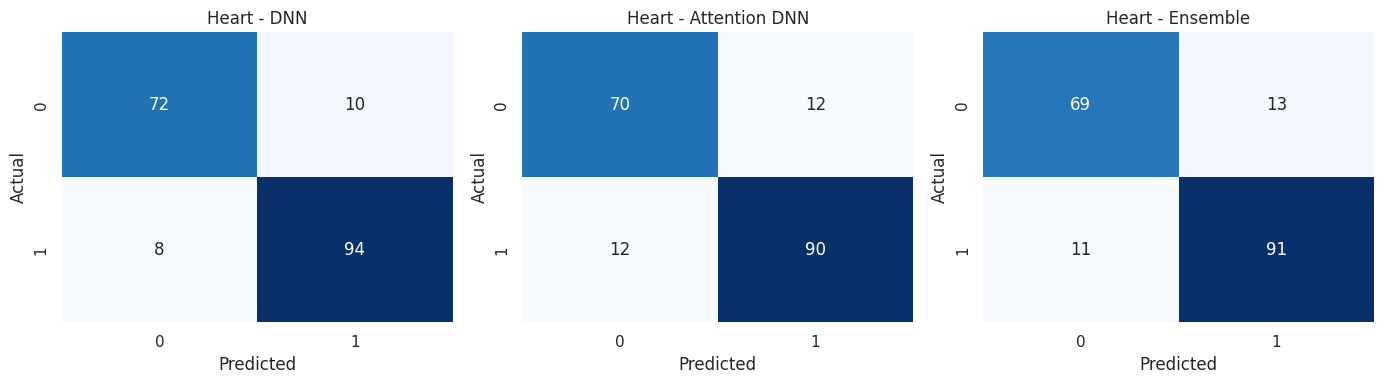

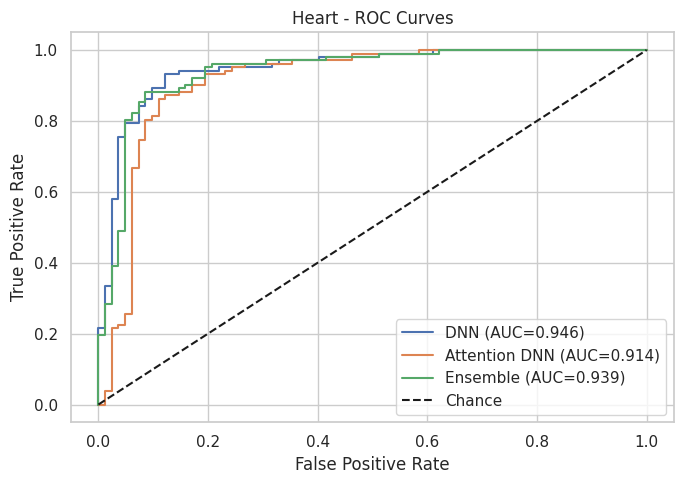

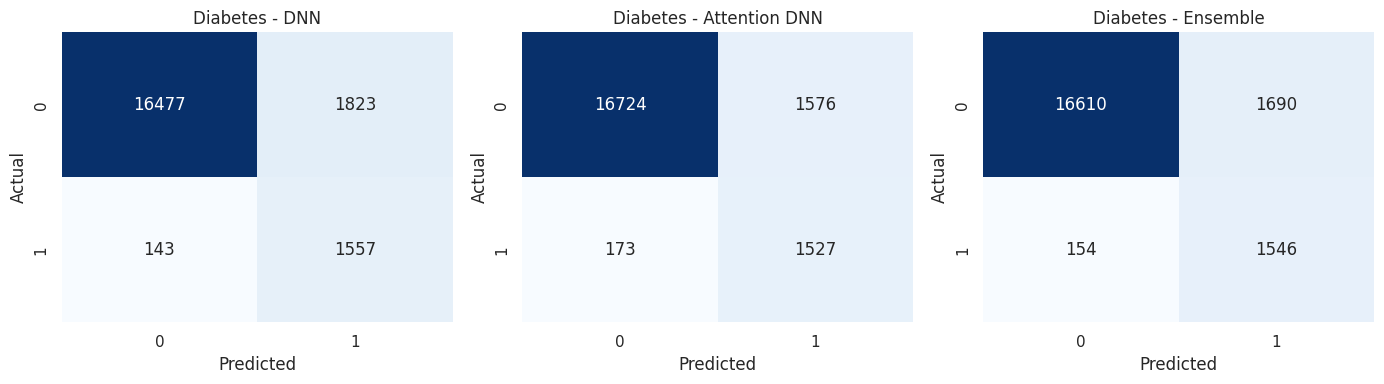

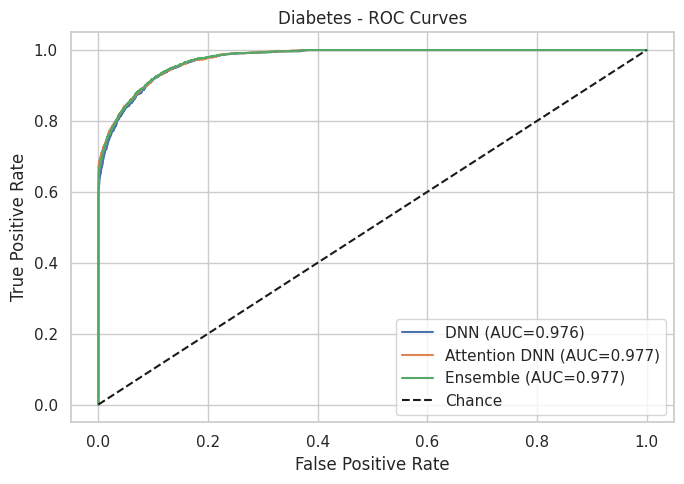

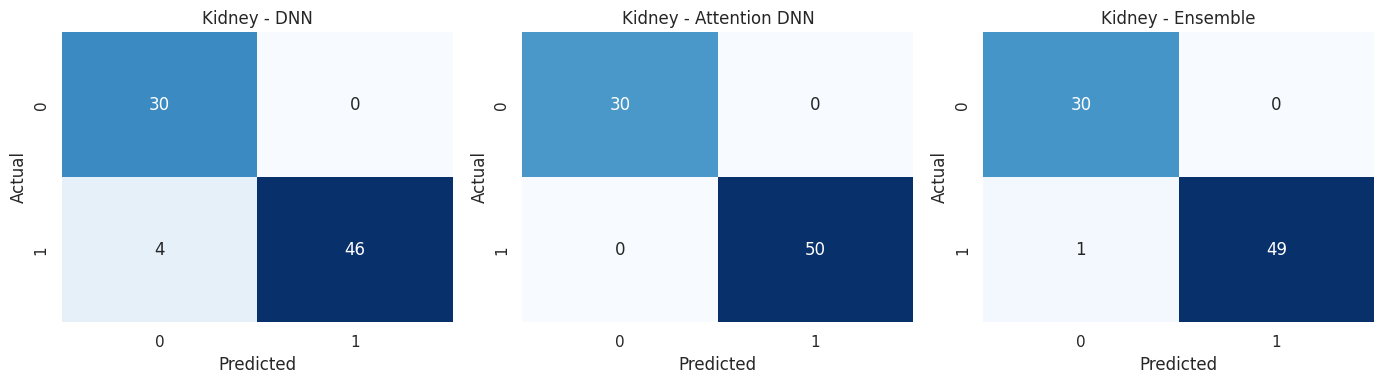

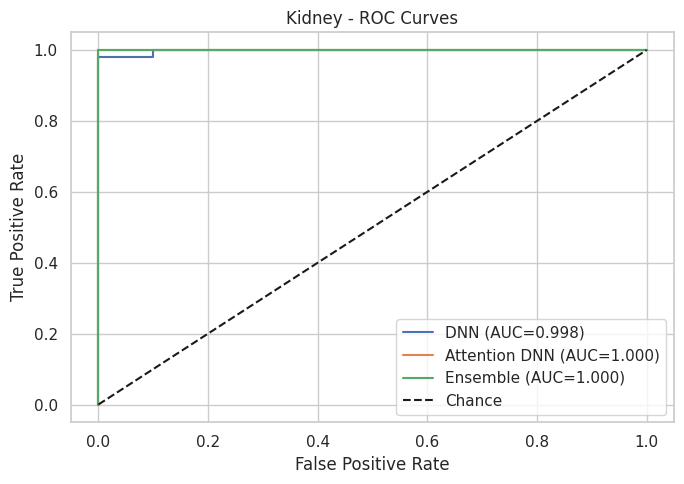

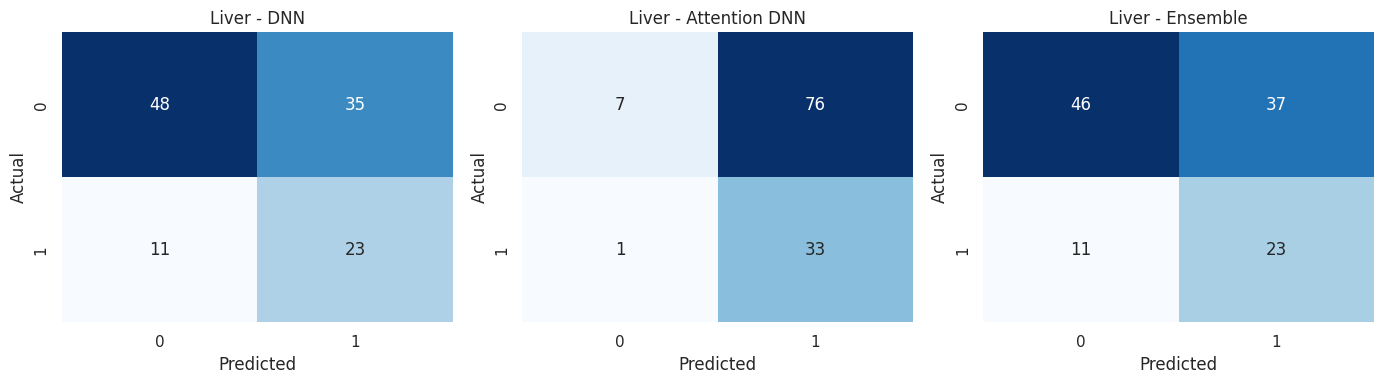

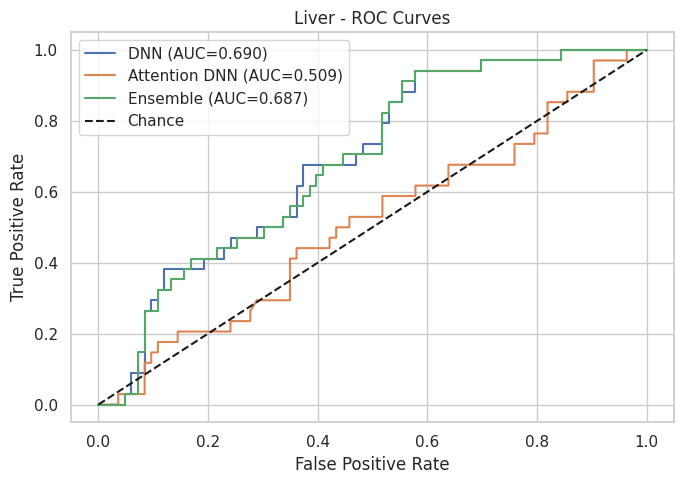

In [ ]:
for disease, item in prepared.items():
    y_true = item["y_test"]
    p_dnn = dnn_models[disease].predict(item["X_test"], verbose=0).ravel()
    p_att = attention_models[disease].predict(item["X_test"], verbose=0).ravel()
    p_ens = ensemble_predictions[disease]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (name, probs) in zip(axes, [
        ("DNN", p_dnn), ("Attention DNN", p_att), ("Ensemble", p_ens)
    ]):
        cm = confusion_matrix(y_true, (probs >= 0.5).astype(int), labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(f"{disease} - {name}")
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    for name, probs in [("DNN", p_dnn), ("Attention DNN", p_att), ("Ensemble", p_ens)]:
        fpr, tpr, _ = roc_curve(y_true, probs)
        auc_value = roc_auc_score(y_true, probs)
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="Chance")
    plt.title(f"{disease} - ROC Curves")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.legend(); plt.tight_layout(); plt.show()

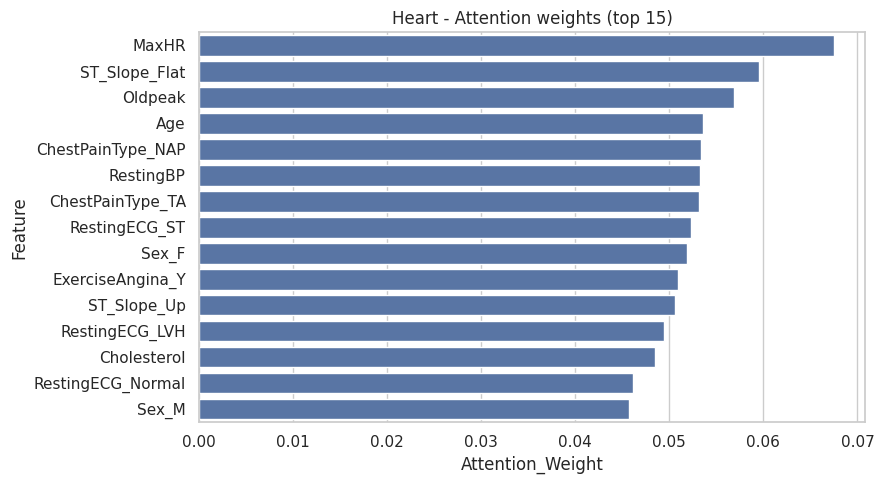

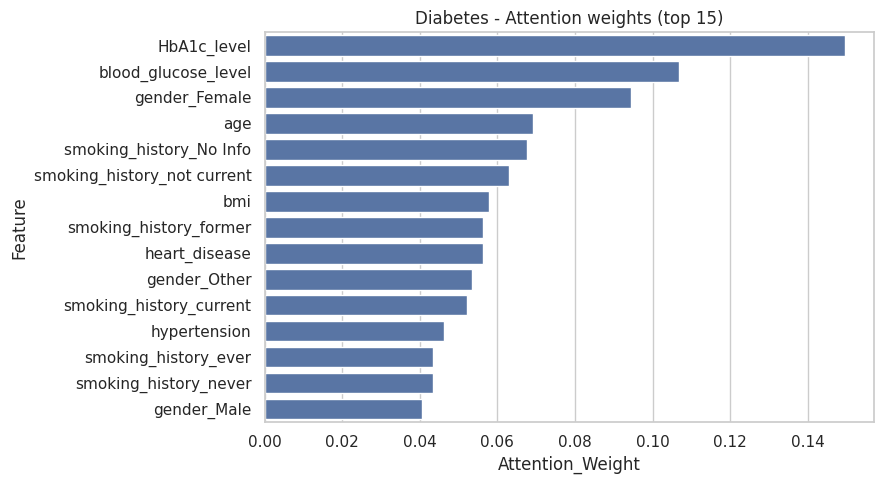

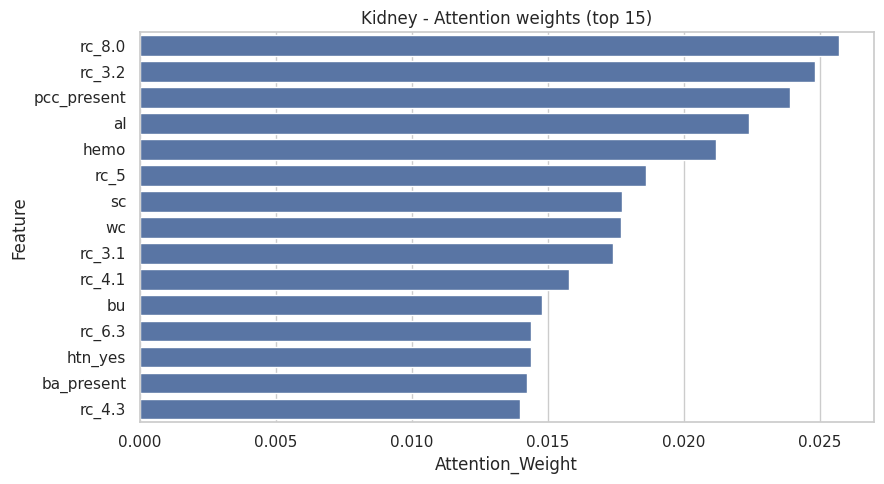

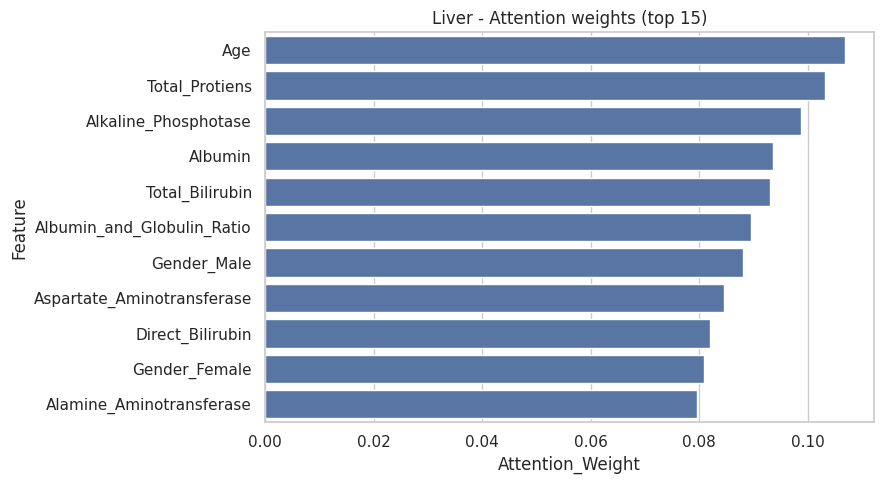

In [ ]:
for disease, model in attention_models.items():
    item = prepared[disease]
    attention_layer_model = keras.Model(
        inputs=model.input,
        outputs=model.get_layer("feature_attention").output
    )
    weights = attention_layer_model.predict(item["X_test"], verbose=0)
    mean_weights = weights.mean(axis=0)
    att_df = pd.DataFrame({
        "Feature": item["feature_names"],
        "Attention_Weight": mean_weights
    }).sort_values("Attention_Weight", ascending=False).head(15)
    plt.figure(figsize=(9, 5))
    sns.barplot(data=att_df, x="Attention_Weight", y="Feature")
    plt.title(f"{disease} - Attention weights (top 15)")
    plt.tight_layout(); plt.show()

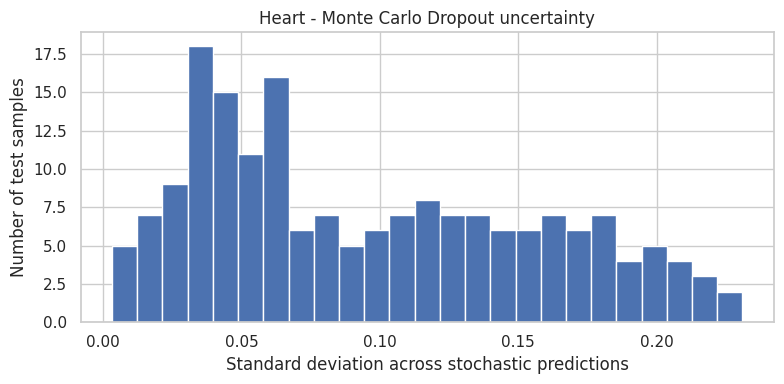

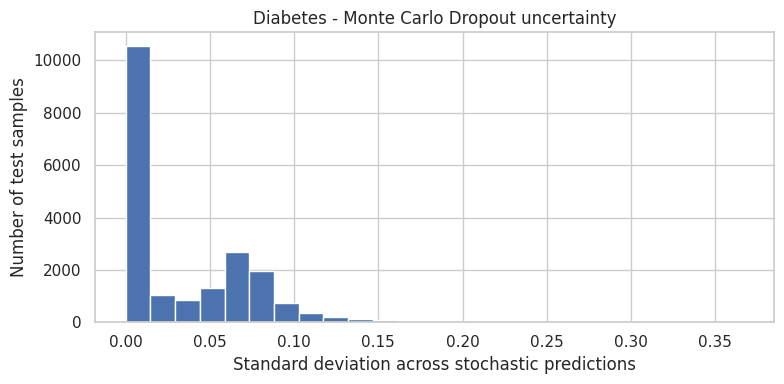

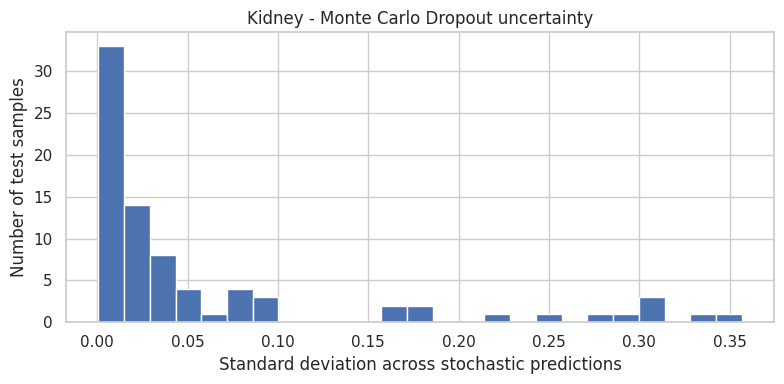

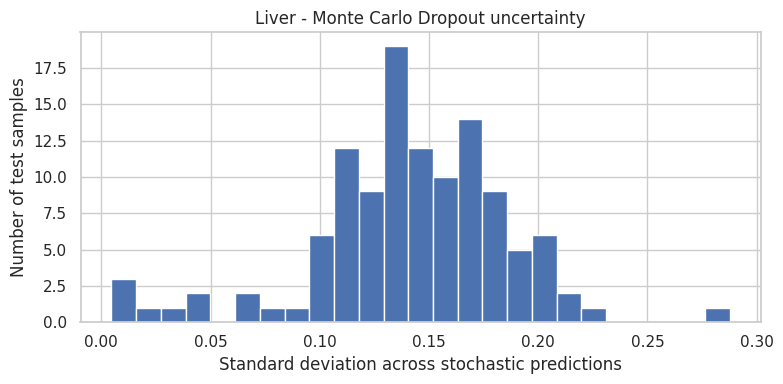

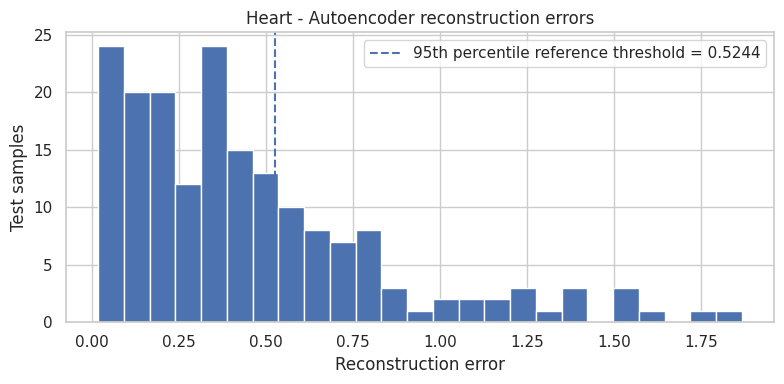

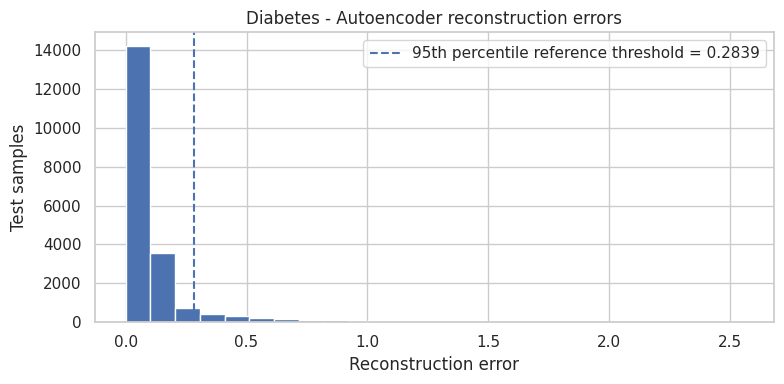

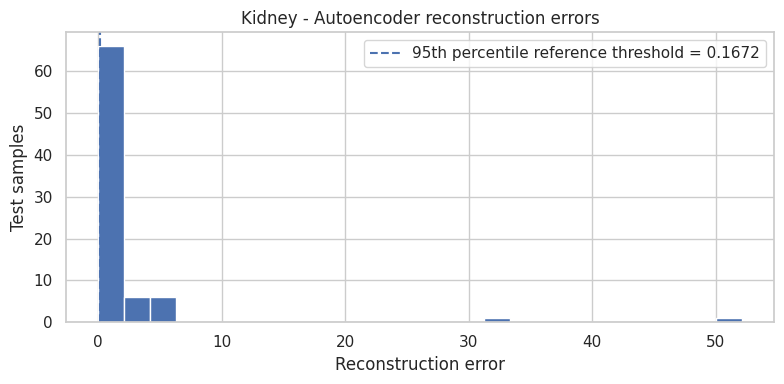

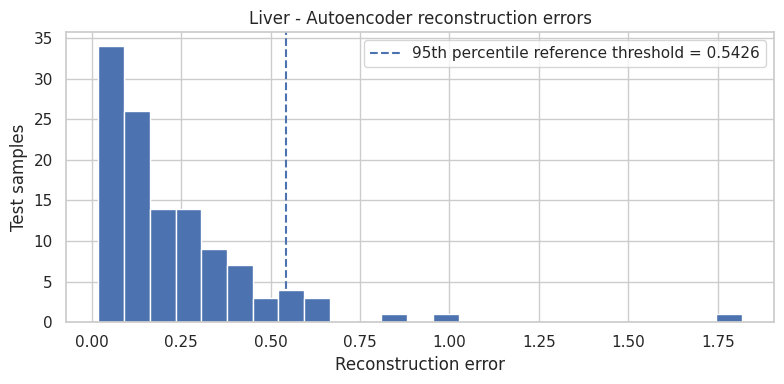

In [ ]:
for disease, output in mc_outputs.items():
    plt.figure(figsize=(8, 4))
    plt.hist(output["std"], bins=25)
    plt.title(f"{disease} - Monte Carlo Dropout uncertainty")
    plt.xlabel("Standard deviation across stochastic predictions")
    plt.ylabel("Number of test samples")
    plt.tight_layout(); plt.show()

for disease, output in anomaly_outputs.items():
    plt.figure(figsize=(8, 4))
    plt.hist(output["errors"], bins=25)
    plt.axvline(output["threshold"], linestyle="--",
                label=f"95th percentile reference threshold = {output['threshold']:.4f}")
    plt.title(f"{disease} - Autoencoder reconstruction errors")
    plt.xlabel("Reconstruction error"); plt.ylabel("Test samples")
    plt.legend(); plt.tight_layout(); plt.show()

,Disease,Model,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC_AUC
5,Diabetes,Attention DNN,0.9126,0.9061,0.4921,0.8982,0.9139,0.6359,0.9770
9,Diabetes,DNN + Attention Ensemble,0.9078,0.9085,0.4778,0.9094,0.9077,0.6264,0.9770
1,Diabetes,DNN,0.9018,0.9082,0.4609,0.9159,0.9005,0.6132,0.9757
0,Heart,DNN,0.8967,0.8949,0.9029,0.9118,0.8780,0.9073,0.9474
8,Heart,DNN + Attention Ensemble,0.8696,0.8668,0.8750,0.8922,0.8415,0.8835,0.9393
4,Heart,Attention DNN,0.8696,0.8680,0.8824,0.8824,0.8537,0.8824,0.9139
6,Kidney,Attention DNN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
10,Kidney,DNN + Attention Ensemble,0.9875,0.9900,1.0000,0.9800,1.0000,0.9899,1.0000
2,Kidney,DNN,0.9500,0.9600,1.0000,0.9200,1.0000,0.9583,0.9993
11,Liver,DNN + Attention Ensemble,0.5897,0.6153,0.3833,0.6765,0.5542,0.4894,0.6867


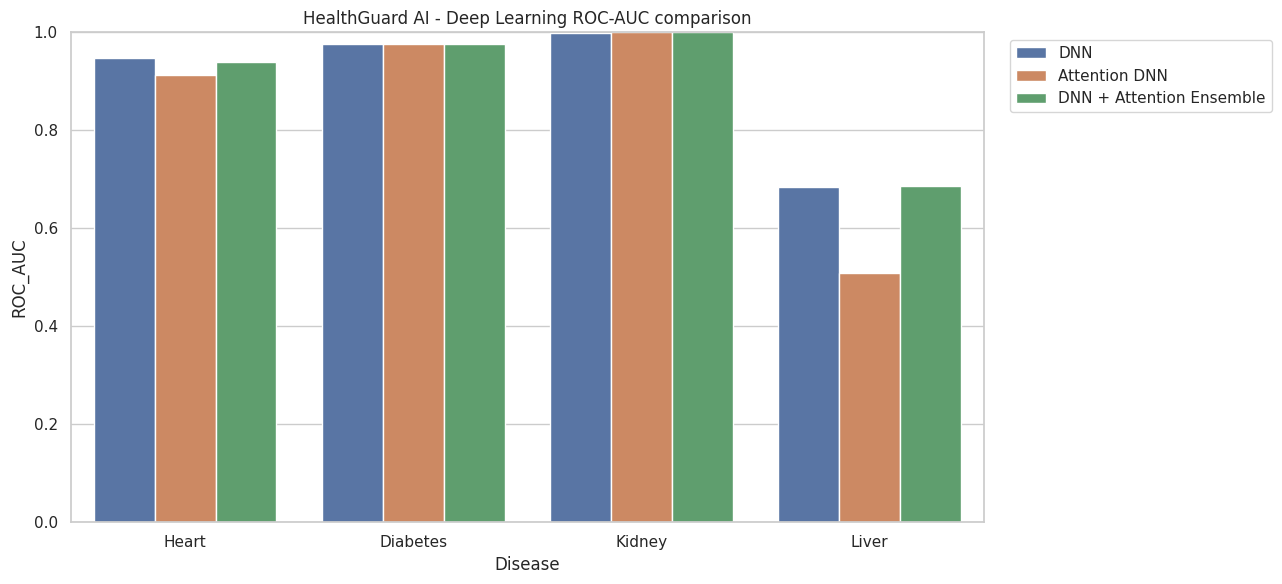

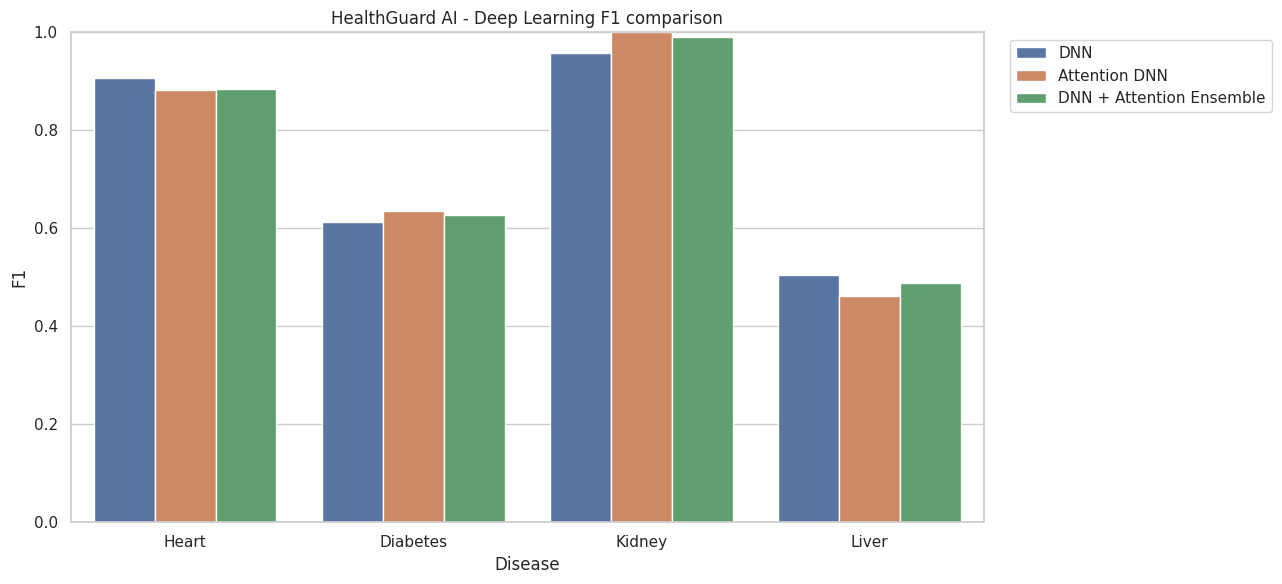

In [ ]:
results_df = pd.DataFrame(all_results)
display(results_df.sort_values(["Disease", "ROC_AUC"], ascending=[True, False]).round(4))

plt.figure(figsize=(13, 6))
sns.barplot(data=results_df, x="Disease", y="ROC_AUC", hue="Model")
plt.title("HealthGuard AI - Deep Learning ROC-AUC comparison")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

plt.figure(figsize=(13, 6))
sns.barplot(data=results_df, x="Disease", y="F1", hue="Model")
plt.title("HealthGuard AI - Deep Learning F1 comparison")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

,Date,Heart_Rate,Systolic_BP,Diastolic_BP,Blood_Glucose,SpO2
0,2026-11-11,80.0,125.0,81.0,97.0,96.7
1,2026-11-12,73.0,116.0,81.0,108.0,98.5
2,2026-11-13,82.0,125.0,90.0,106.0,96.1
3,2026-11-14,83.0,115.0,77.0,108.0,98.0
4,2026-11-15,68.0,128.0,76.0,115.0,95.3
5,2026-11-16,71.0,122.0,75.0,108.0,96.7
6,2026-11-17,79.0,121.0,82.0,113.0,97.2
7,2026-11-18,76.0,117.0,85.0,106.0,97.6
8,2026-11-19,78.0,131.0,78.0,108.0,97.7
9,2026-11-20,74.0,121.0,75.0,113.0,97.8


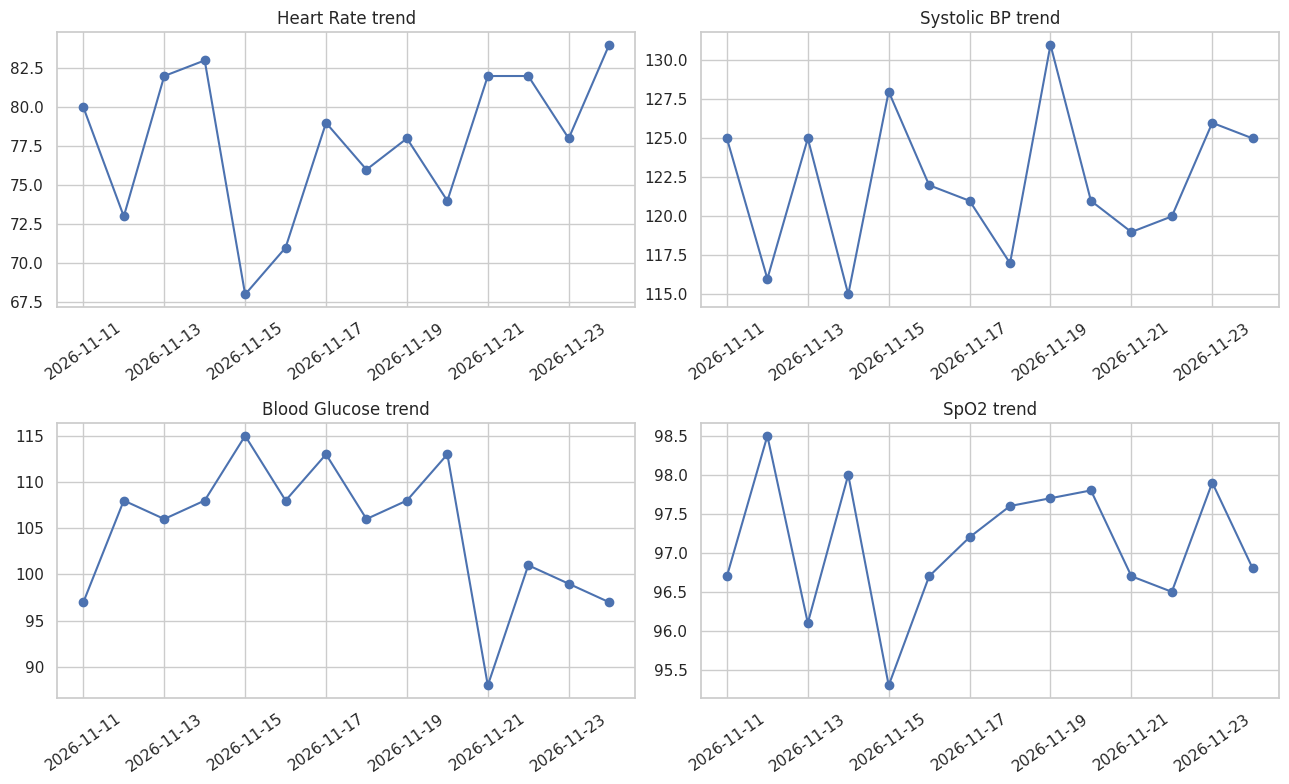

Synthetic monitoring demo exported.


In [ ]:
demo_dates = pd.date_range(end=pd.Timestamp.today().normalize(), periods=14, freq="D")
rng = np.random.default_rng(SEED)
demo_patient = pd.DataFrame({
    "Date": demo_dates,
    "Heart_Rate": rng.normal(78, 5, 14).round(0),
    "Systolic_BP": rng.normal(122, 7, 14).round(0),
    "Diastolic_BP": rng.normal(79, 5, 14).round(0),
    "Blood_Glucose": rng.normal(105, 12, 14).round(0),
    "SpO2": rng.normal(97, 1, 14).round(1)
})
display(demo_patient)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ["Heart_Rate", "Systolic_BP", "Blood_Glucose", "SpO2"]):
    ax.plot(demo_patient["Date"], demo_patient[col], marker="o")
    ax.set_title(col.replace("_", " ") + " trend")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

demo_patient.to_csv("HealthGuard_Demo_Patient_Monitoring.csv", index=False)
print("Synthetic monitoring demo exported.")

In [ ]:
OUTPUT_DIR = Path("/content/HealthGuard_Outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

results_df.to_csv(OUTPUT_DIR / "DeepLearning_Model_Comparison.csv", index=False)
profile_df.to_csv(OUTPUT_DIR / "Dataset_Profile.csv", index=False)

for disease, model in dnn_models.items():
    safe = disease.lower().replace(" ", "_")
    model.save(OUTPUT_DIR / f"{safe}_dnn.keras")

for disease, model in attention_models.items():
    safe = disease.lower().replace(" ", "_")
    model.save(OUTPUT_DIR / f"{safe}_attention_dnn.keras")

for disease, importance in ig_importance.items():
    safe = disease.lower().replace(" ", "_")
    importance.to_csv(OUTPUT_DIR / f"{safe}_integrated_gradients.csv", index=False)

demo_patient.to_csv(OUTPUT_DIR / "Synthetic_Patient_Monitoring.csv", index=False)

print("Saved project outputs to:", OUTPUT_DIR)
print("Files:")
for f in sorted(OUTPUT_DIR.iterdir()):
    print("-", f.name)

Saved project outputs to: /content/HealthGuard_Outputs
Files:
- Dataset_Profile.csv
- DeepLearning_Model_Comparison.csv
- Synthetic_Patient_Monitoring.csv
- diabetes_attention_dnn.keras
- diabetes_dnn.keras
- diabetes_integrated_gradients.csv
- heart_attention_dnn.keras
- heart_dnn.keras
- heart_integrated_gradients.csv
- kidney_attention_dnn.keras
- kidney_dnn.keras
- kidney_integrated_gradients.csv
- liver_attention_dnn.keras
- liver_dnn.keras
- liver_integrated_gradients.csv


In [ ]:
required_objects = [
    "prepared", "dnn_models", "attention_models",
    "ensemble_predictions", "mc_outputs",
    "anomaly_outputs", "ig_importance", "results_df"
]
missing = [name for name in required_objects if name not in globals()]
if missing:
    raise RuntimeError(
        "Run the first notebook successfully before this continuation. "
        "Missing objects: " + ", ".join(missing)
    )

print("Previous sections are ready.")
print("Disease datasets:", list(prepared.keys()))
print("DNN models:", list(dnn_models.keys()))
print("Attention models:", list(attention_models.keys()))

In [ ]:
deep_ensemble_models = {}
deep_ensemble_outputs = {}

N_ENSEMBLE_MODELS = 3  # Increase to 5 if Colab GPU/time permits.

for disease, item in prepared.items():
    models_for_disease = []
    predictions_for_disease = []

    print(f"Training {N_ENSEMBLE_MODELS} DNN ensemble members for {disease}")

    for member in range(N_ENSEMBLE_MODELS):
        tf.keras.utils.set_random_seed(SEED + 100 + member)
        model = build_dnn(item["X_train"].shape[1])

        classes = np.unique(item["y_train"])
        weights = compute_class_weight(
            class_weight="balanced",
            classes=classes,
            y=item["y_train"]
        )
        class_weights = {
            int(label): float(weight)
            for label, weight in zip(classes, weights)
        }

        model.fit(
            item["X_train"], item["y_train"],
            validation_split=0.20,
            epochs=100,
            batch_size=32,
            callbacks=make_callbacks(),
            class_weight=class_weights,
            verbose=0
        )

        member_prob = model.predict(item["X_test"], verbose=0).ravel()
        models_for_disease.append(model)
        predictions_for_disease.append(member_prob)

    prediction_matrix = np.vstack(predictions_for_disease)
    mean_probability = prediction_matrix.mean(axis=0)
    member_disagreement = prediction_matrix.std(axis=0)

    deep_ensemble_models[disease] = models_for_disease
    deep_ensemble_outputs[disease] = {
        "member_probabilities": prediction_matrix,
        "mean_probability": mean_probability,
        "disagreement": member_disagreement
    }

    metrics = evaluate_binary(item["y_test"], mean_probability)
    all_results.append({
        "Disease": disease,
        "Model": "Independent DNN Ensemble (3 members)",
        **metrics
    })
    print(metrics)

print("Independent deep ensembles completed.")

Training 3 DNN ensemble members for Heart
{'Accuracy': 0.875, 'Balanced Accuracy': np.float64(0.8788857006217121), 'Precision': 0.9247311827956989, 'Recall': 0.8431372549019608, 'Specificity': np.float64(0.9146341463414634), 'F1': 0.882051282051282, 'ROC_AUC': np.float64(0.9332855093256814)}
Training 3 DNN ensemble members for Diabetes
{'Accuracy': 0.9007, 'Balanced Accuracy': np.float64(0.9099871423979428), 'Precision': 0.45816266822703333, 'Recall': 0.9211764705882353, 'Specificity': np.float64(0.8987978142076503), 'F1': 0.611957796014068, 'ROC_AUC': np.float64(0.9768159755705561)}
Training 3 DNN ensemble members for Kidney
{'Accuracy': 0.975, 'Balanced Accuracy': np.float64(0.98), 'Precision': 1.0, 'Recall': 0.96, 'Specificity': np.float64(1.0), 'F1': 0.9795918367346939, 'ROC_AUC': np.float64(1.0)}
Training 3 DNN ensemble members for Liver
{'Accuracy': 0.6410256410256411, 'Balanced Accuracy': np.float64(0.5820340184266477), 'Precision': 0.39473684210526316, 'Recall': 0.4411764705882

In [144]:
denoising_autoencoders = {}
denoising_history = {}

for disease, item in prepared.items():
    X_train = item["X_train"]
    input_dim = X_train.shape[1]
    latent_dim = max(2, min(32, input_dim // 2))

    inp = keras.Input(shape=(input_dim,))
    noisy = layers.GaussianNoise(0.10)(inp)
    x = layers.Dense(max(16, latent_dim * 2), activation="relu")(noisy)
    z = layers.Dense(latent_dim, activation="relu", name="denoising_latent")(x)
    x = layers.Dense(max(16, latent_dim * 2), activation="relu")(z)
    out = layers.Dense(input_dim, activation="linear")(x)

    dae = keras.Model(inp, out, name=f"{disease}_Denoising_Autoencoder")
    dae.compile(optimizer="adam", loss="mse")

    history = dae.fit(
        X_train, X_train,
        validation_split=0.20,
        epochs=80,
        batch_size=32,
        callbacks=make_callbacks(),
        verbose=0
    )

    denoising_autoencoders[disease] = dae
    denoising_history[disease] = history
    print(disease, "| final validation loss:",
          round(float(history.history["val_loss"][-1]), 5))

print("Denoising autoencoder experiments completed.")

Heart | final validation loss: 0.20375
Diabetes | final validation loss: 0.0043
Kidney | final validation loss: 0.61343
Liver | final validation loss: 0.13091
Denoising autoencoder experiments completed.


,Disease,Autoencoder,Mean Test Reconstruction Error
0,Heart,Reference Autoencoder,0.45479
1,Heart,Denoising Autoencoder,0.22799
2,Diabetes,Reference Autoencoder,0.11244
3,Diabetes,Denoising Autoencoder,0.00353
4,Kidney,Reference Autoencoder,1.92778
5,Kidney,Denoising Autoencoder,1.47237
6,Liver,Reference Autoencoder,0.22923
7,Liver,Denoising Autoencoder,0.15362


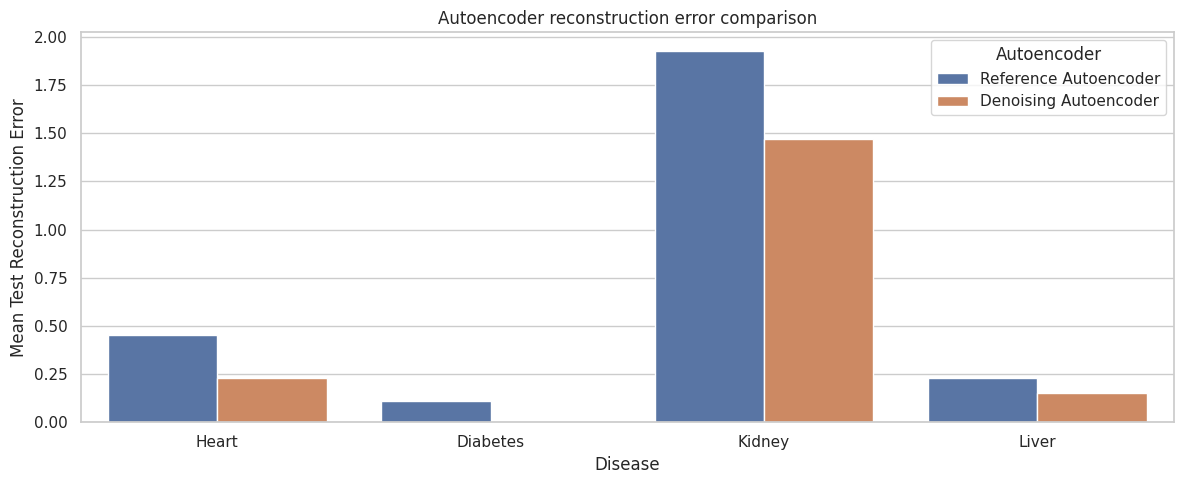

In [145]:
reconstruction_comparison = []

for disease, item in prepared.items():
    X_test = item["X_test"]

    if disease in autoencoders:
        rec = autoencoders[disease].predict(X_test, verbose=0)
        err = np.mean((X_test - rec) ** 2, axis=1)
        reconstruction_comparison.append({
            "Disease": disease,
            "Autoencoder": "Reference Autoencoder",
            "Mean Test Reconstruction Error": float(err.mean())
        })

    if disease in denoising_autoencoders:
        rec = denoising_autoencoders[disease].predict(X_test, verbose=0)
        err = np.mean((X_test - rec) ** 2, axis=1)
        reconstruction_comparison.append({
            "Disease": disease,
            "Autoencoder": "Denoising Autoencoder",
            "Mean Test Reconstruction Error": float(err.mean())
        })

reconstruction_df = pd.DataFrame(reconstruction_comparison)
display(reconstruction_df.round(5))

if not reconstruction_df.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(
        data=reconstruction_df,
        x="Disease",
        y="Mean Test Reconstruction Error",
        hue="Autoencoder"
    )
    plt.title("Autoencoder reconstruction error comparison")
    plt.tight_layout()
    plt.show()

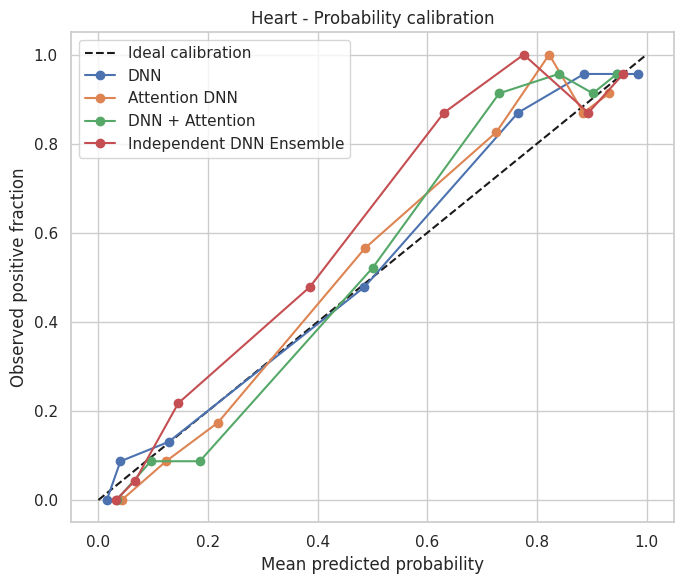

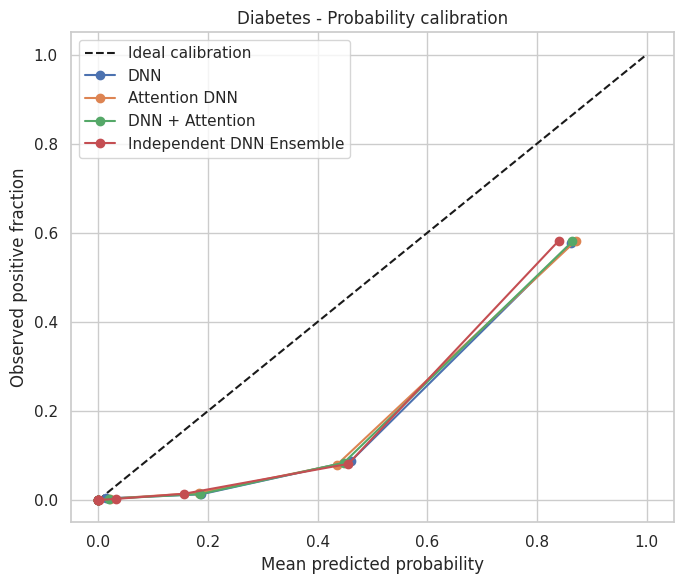

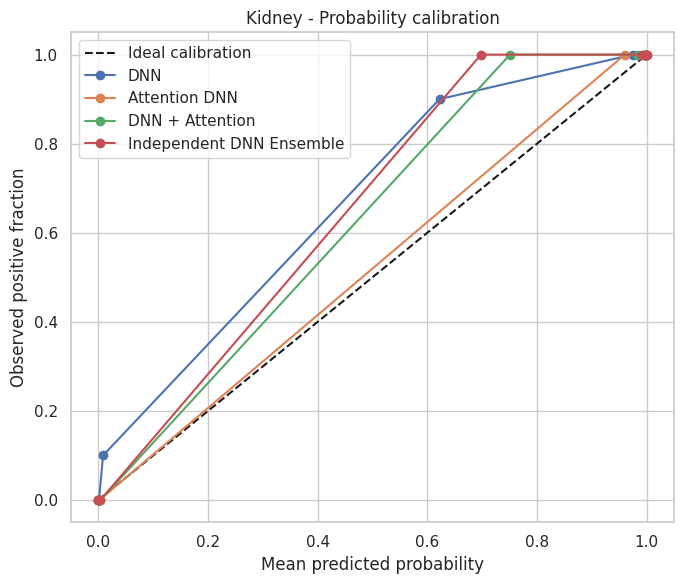

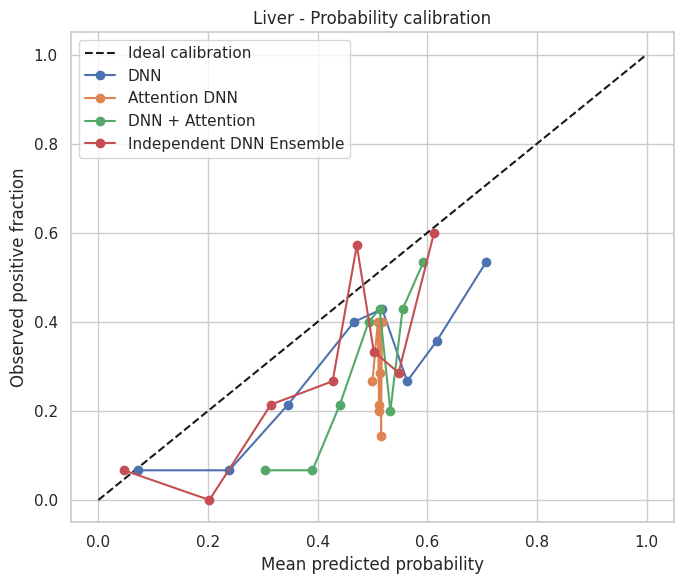

,Disease,Model,Brier Score
0,Heart,DNN,0.0851
1,Heart,Attention DNN,0.1053
2,Heart,DNN + Attention,0.0908
3,Heart,Independent DNN Ensemble,0.1032
4,Diabetes,DNN,0.0654
5,Diabetes,Attention DNN,0.0625
6,Diabetes,DNN + Attention,0.0635
7,Diabetes,Independent DNN Ensemble,0.0607
8,Kidney,DNN,0.0316
9,Kidney,Attention DNN,0.0006


In [146]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

calibration_rows = []

for disease, item in prepared.items():
    y_true = item["y_test"]
    model_probabilities = {
        "DNN": dnn_models[disease].predict(item["X_test"], verbose=0).ravel(),
        "Attention DNN": attention_models[disease].predict(item["X_test"], verbose=0).ravel(),
        "DNN + Attention": ensemble_predictions[disease]
    }

    if disease in deep_ensemble_outputs:
        model_probabilities["Independent DNN Ensemble"] = (
            deep_ensemble_outputs[disease]["mean_probability"]
        )

    plt.figure(figsize=(7, 6))
    plt.plot([0, 1], [0, 1], "k--", label="Ideal calibration")

    for model_name, probs in model_probabilities.items():
        brier = brier_score_loss(y_true, probs)
        fraction_positive, mean_predicted = calibration_curve(
            y_true, probs, n_bins=8, strategy="quantile"
        )
        plt.plot(mean_predicted, fraction_positive, marker="o", label=model_name)
        calibration_rows.append({
            "Disease": disease,
            "Model": model_name,
            "Brier Score": brier
        })

    plt.title(f"{disease} - Probability calibration")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed positive fraction")
    plt.legend()
    plt.tight_layout()
    plt.show()

calibration_df = pd.DataFrame(calibration_rows)
display(calibration_df.round(4))

In [147]:
def bootstrap_auc_ci(y_true, probabilities, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    scores = []

    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        y_sample = y_true[idx]
        p_sample = probabilities[idx]
        if len(np.unique(y_sample)) < 2:
            continue
        scores.append(roc_auc_score(y_sample, p_sample))

    if len(scores) < 20:
        return np.nan, np.nan, np.nan

    return (
        float(np.mean(scores)),
        float(np.percentile(scores, 2.5)),
        float(np.percentile(scores, 97.5))
    )

auc_intervals = []
for disease, item in prepared.items():
    probability_sets = {
        "DNN": dnn_models[disease].predict(item["X_test"], verbose=0).ravel(),
        "Attention DNN": attention_models[disease].predict(item["X_test"], verbose=0).ravel(),
        "DNN + Attention": ensemble_predictions[disease]
    }
    probability_sets["Independent DNN Ensemble"] = (
        deep_ensemble_outputs[disease]["mean_probability"]
    )

    for model_name, probs in probability_sets.items():
        mean_auc, low, high = bootstrap_auc_ci(
            item["y_test"], probs, n_boot=1000, seed=SEED
        )
        auc_intervals.append({
            "Disease": disease,
            "Model": model_name,
            "Bootstrap Mean AUC": mean_auc,
            "95% CI Lower": low,
            "95% CI Upper": high
        })

auc_ci_df = pd.DataFrame(auc_intervals)
display(auc_ci_df.round(4))

,Disease,Model,Bootstrap Mean AUC,95% CI Lower,95% CI Upper
0,Heart,DNN,0.9463,0.9115,0.9747
1,Heart,Attention DNN,0.9141,0.8636,0.9562
2,Heart,DNN + Attention,0.9394,0.9004,0.9710
3,Heart,Independent DNN Ensemble,0.9333,0.8910,0.9668
4,Diabetes,DNN,0.9757,0.9731,0.9783
5,Diabetes,Attention DNN,0.9770,0.9744,0.9796
6,Diabetes,DNN + Attention,0.9770,0.9743,0.9796
7,Diabetes,Independent DNN Ensemble,0.9768,0.9743,0.9795
8,Kidney,DNN,0.9978,0.9908,1.0000
9,Kidney,Attention DNN,1.0000,1.0000,1.0000


In [ ]:
def mean_integrated_gradient_importance(model, X, max_samples=100):
    n = min(max_samples, len(X))
    values = []
    for row in X[:n]:
        values.append(integrated_gradients(model, row).numpy())
    return np.mean(np.abs(np.asarray(values)), axis=0)

attribution_comparisons = {}

for disease, item in prepared.items():
    dnn_attr = mean_integrated_gradient_importance(
        dnn_models[disease], item["X_test"]
    )
    attention_attr = mean_integrated_gradient_importance(
        attention_models[disease], item["X_test"]
    )

    comparison = pd.DataFrame({
        "Feature": item["feature_names"],
        "DNN_Attribution": dnn_attr,
        "Attention_DNN_Attribution": attention_attr
    })
    comparison["Combined_Mean_Attribution"] = comparison[
        ["DNN_Attribution", "Attention_DNN_Attribution"]
    ].mean(axis=1)
    comparison = comparison.sort_values(
        "Combined_Mean_Attribution", ascending=False
    )

    attribution_comparisons[disease] = comparison
    display(comparison.head(15))

    top = comparison.head(15).sort_values("Combined_Mean_Attribution")
    top.plot(
        x="Feature",
        y=["DNN_Attribution", "Attention_DNN_Attribution"],
        kind="barh",
        figsize=(10, 6)
    )
    plt.title(f"{disease} - Integrated Gradients model comparison")
    plt.tight_layout()
    plt.show()

\n Heart - highest disagreement examples


,Test_Row_Index,Actual_Label,DNN_Probability,Attention_Probability,Absolute_Disagreement
130,130,0,0.116069,0.968470,0.852400
115,115,1,0.125813,0.672170,0.546357
21,21,1,0.845381,0.417749,0.427632
92,92,0,0.094028,0.494550,0.400522
148,148,1,0.959395,0.578169,0.381225
173,173,1,0.897377,0.554733,0.342644
175,175,1,0.624616,0.291007,0.333610
134,134,1,0.922284,0.589778,0.332507
91,91,1,0.798271,0.516023,0.282248
90,90,0,0.426000,0.708233,0.282233


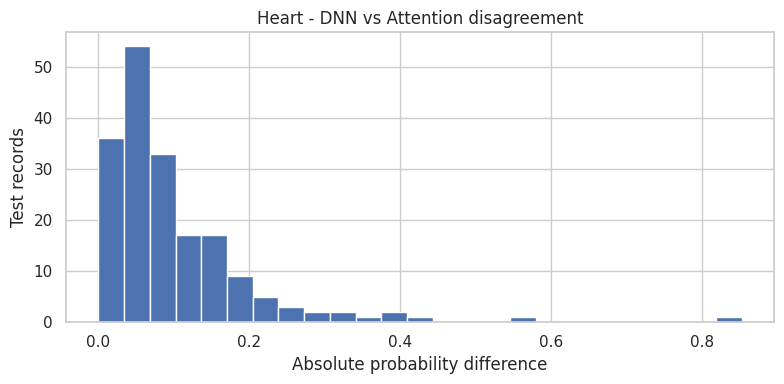

\n Diabetes - highest disagreement examples


,Test_Row_Index,Actual_Label,DNN_Probability,Attention_Probability,Absolute_Disagreement
13027,13027,1,0.285078,0.987254,0.702177
13340,13340,1,0.314637,0.911256,0.596619
8847,8847,1,0.395015,0.990191,0.595175
19687,19687,0,0.723044,0.132591,0.590452
17534,17534,1,0.790778,0.223490,0.567288
8954,8954,0,0.655226,0.100443,0.554783
10963,10963,0,0.665399,0.114531,0.550868
17744,17744,0,0.767524,0.258880,0.508644
9734,9734,0,0.664047,0.168913,0.495134
12266,12266,1,0.471143,0.960325,0.489182


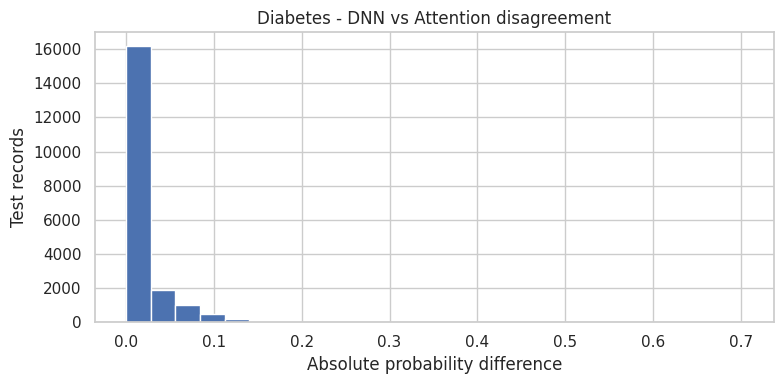

\n Kidney - highest disagreement examples


,Test_Row_Index,Actual_Label,DNN_Probability,Attention_Probability,Absolute_Disagreement
9,9,1,0.016713,0.901204,0.884491
41,41,1,0.129897,0.993522,0.863625
56,56,1,0.426868,0.999833,0.572965
20,20,1,0.416565,0.987126,0.570561
50,50,1,0.772117,0.999616,0.227500
60,60,1,0.840704,0.999901,0.159196
61,61,1,0.834477,0.929410,0.094933
12,12,1,0.916627,0.825398,0.091228
71,71,1,0.914128,0.986825,0.072697
2,2,1,0.939895,0.998339,0.058444


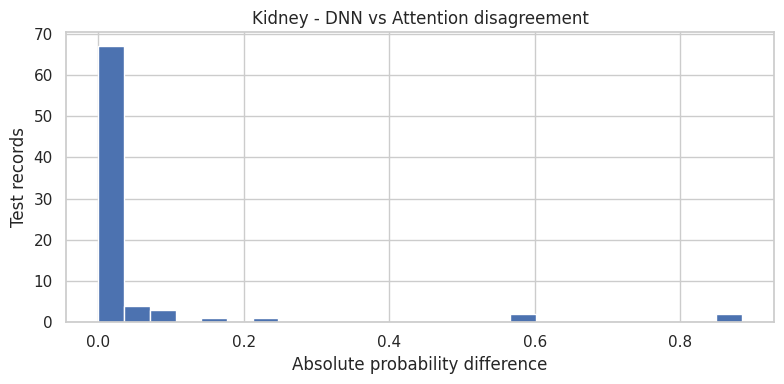

\n Liver - highest disagreement examples


,Test_Row_Index,Actual_Label,DNN_Probability,Attention_Probability,Absolute_Disagreement
68,68,0,0.005742,0.512732,0.506991
109,109,0,0.012469,0.512318,0.499849
94,94,0,0.001600,0.499991,0.498391
54,54,0,0.011768,0.508919,0.497151
56,56,0,0.006565,0.498395,0.491830
62,62,0,0.021073,0.497821,0.476749
44,44,0,0.037547,0.510201,0.472654
21,21,0,0.083562,0.513055,0.429493
85,85,0,0.109595,0.516001,0.406405
26,26,0,0.109595,0.516001,0.406405


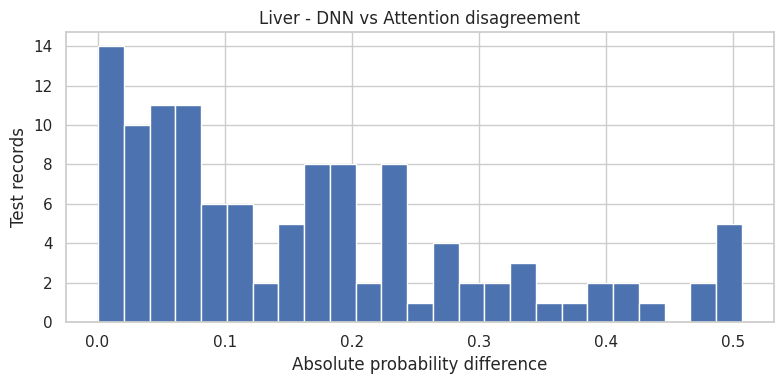

In [ ]:
disagreement_outputs = {}

for disease, item in prepared.items():
    p_dnn = dnn_models[disease].predict(item["X_test"], verbose=0).ravel()
    p_attention = attention_models[disease].predict(item["X_test"], verbose=0).ravel()
    difference = np.abs(p_dnn - p_attention)

    disagreement_df = pd.DataFrame({
        "Test_Row_Index": np.arange(len(difference)),
        "Actual_Label": item["y_test"],
        "DNN_Probability": p_dnn,
        "Attention_Probability": p_attention,
        "Absolute_Disagreement": difference
    }).sort_values("Absolute_Disagreement", ascending=False)

    disagreement_outputs[disease] = disagreement_df
    print("\\n", disease, "- highest disagreement examples")
    display(disagreement_df.head(10))

    plt.figure(figsize=(8, 4))
    plt.hist(difference, bins=25)
    plt.title(f"{disease} - DNN vs Attention disagreement")
    plt.xlabel("Absolute probability difference")
    plt.ylabel("Test records")
    plt.tight_layout()
    plt.show()

In [ ]:
extended_results_df = pd.DataFrame(all_results)
metric_columns = ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC_AUC"]

for disease in extended_results_df["Disease"].unique():
    subset = extended_results_df[extended_results_df["Disease"] == disease]
    heatmap_data = subset.set_index("Model")[metric_columns]
    plt.figure(figsize=(11, max(3, 0.65 * len(heatmap_data))))
    sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1)
    plt.title(f"{disease} - Deep Learning metric heatmap")
    plt.tight_layout()
    plt.show()

display(extended_results_df.sort_values(["Disease", "ROC_AUC"], ascending=[True, False]).round(4))

In [ ]:
def demonstrate_model_scores(disease, test_row_number=0):
    if disease not in prepared:
        raise KeyError(f"Unknown disease: {disease}")

    item = prepared[disease]
    if not 0 <= test_row_number < len(item["X_test"]):
        raise IndexError("Test row number is outside the available test data.")

    row = item["X_test"][test_row_number:test_row_number + 1]

    p_dnn = float(dnn_models[disease].predict(row, verbose=0)[0, 0])
    p_attention = float(attention_models[disease].predict(row, verbose=0)[0, 0])
    p_ensemble = float(ensemble_predictions[disease][test_row_number])

    output = {
        "Dataset": disease,
        "Test record index": test_row_number,
        "DNN model score": round(p_dnn, 4),
        "Attention DNN model score": round(p_attention, 4),
        "Combined neural model score": round(p_ensemble, 4),
        "Actual dataset label": int(item["y_test"][test_row_number])
    }
    return pd.DataFrame([output])

# Example only: view the first held-out test record for each disease.
for disease in prepared:
    display(demonstrate_model_scores(disease, 0))

print("These are experimental model scores, not clinical risk estimates or diagnoses.")

,Dataset,Test record index,DNN model score,Attention DNN model score,Combined neural model score,Actual dataset label
0,Heart,0,0.987,0.879,0.9304,1


,Dataset,Test record index,DNN model score,Attention DNN model score,Combined neural model score,Actual dataset label
0,Diabetes,0,0.1221,0.2291,0.1756,0


,Dataset,Test record index,DNN model score,Attention DNN model score,Combined neural model score,Actual dataset label
0,Kidney,0,0.0001,0.0,0.0,0


,Dataset,Test record index,DNN model score,Attention DNN model score,Combined neural model score,Actual dataset label
0,Liver,0,0.4826,0.5135,0.4979,0


These are experimental model scores, not clinical risk estimates or diagnoses.


In [10]:
from pathlib import Path
import pandas as pd
import tensorflow as tf

ADVANCED_OUTPUT_DIR = Path("/content/HealthGuard_Advanced_Outputs")
ADVANCED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASIC_OUTPUT_DIR = Path("/content/HealthGuard_Outputs")

# Fallback loading strategy if runtime was reset
if "all_results" in globals():
    extended_results_df = pd.DataFrame(all_results)
elif "results" in globals():
    extended_results_df = pd.DataFrame(results)
elif BASIC_OUTPUT_DIR.exists() and (BASIC_OUTPUT_DIR / "DeepLearning_Model_Comparison.csv").exists():
    print("Runtime memory cleared. Loading saved metrics from disk...")
    extended_results_df = pd.read_csv(BASIC_OUTPUT_DIR / "DeepLearning_Model_Comparison.csv")
else:
    print("No active results found. Creating an empty DataFrame as placeholder.")
    extended_results_df = pd.DataFrame()

extended_results_df.to_csv(
    ADVANCED_OUTPUT_DIR / "All_DeepLearning_Metrics.csv", index=False
)

# Safeguard for other non-essential validation dataframes
for df_name, file_name in [
    ("reconstruction_df", "Autoencoder_Comparison.csv"),
    ("calibration_df", "Calibration_Brier_Scores.csv"),
    ("auc_ci_df", "Bootstrap_AUC_Confidence_Intervals.csv")
]:
    if df_name in globals():
        globals()[df_name].to_csv(ADVANCED_OUTPUT_DIR / file_name, index=False)
    else:
        pd.DataFrame().to_csv(ADVANCED_OUTPUT_DIR / file_name, index=False)

# Save feature attributions and disagreements if they exist in memory
for disease_dict, name_suffix in [
    ("attribution_comparisons", "Attribution_Comparison"),
    ("disagreement_outputs", "Model_Disagreement")
]:
    if disease_dict in globals():
        for disease, df in globals()[disease_dict].items():
            safe = disease.lower().replace(" ", "_")
            df.to_csv(ADVANCED_OUTPUT_DIR / f"{safe}_{name_suffix}.csv", index=False)

# Copy model files over if they exist in the previous outputs folder
if BASIC_OUTPUT_DIR.exists():
    for keras_file in BASIC_OUTPUT_DIR.glob("*.keras"):
        import shutil
        shutil.copy(keras_file, ADVANCED_OUTPUT_DIR / keras_file.name)

print("Advanced outputs processed:")
for file in sorted(ADVANCED_OUTPUT_DIR.iterdir()):
    print(file.name)

No active results found. Creating an empty DataFrame as placeholder.
Advanced outputs processed:
All_DeepLearning_Metrics.csv
Autoencoder_Comparison.csv
Bootstrap_AUC_Confidence_Intervals.csv
Calibration_Brier_Scores.csv


In [ ]:
import shutil

zip_base = "/content/HealthGuard_Advanced_Outputs"
zip_path = shutil.make_archive(zip_base, "zip", ADVANCED_OUTPUT_DIR)

print("ZIP created:", zip_path)
print("In Google Colab, use the Files panel to download HealthGuard_Advanced_Outputs.zip.")

ZIP created: /content/HealthGuard_Advanced_Outputs.zip
In Google Colab, use the Files panel to download HealthGuard_Advanced_Outputs.zip.


In [ ]:
final_required = [
    "prepared", "dnn_models", "attention_models",
    "ensemble_predictions", "mc_outputs", "anomaly_outputs",
    "ig_importance", "extended_results_df",
    "ADVANCED_OUTPUT_DIR"
]
missing_final = [name for name in final_required if name not in globals()]
if missing_final:
    raise RuntimeError(
        "Some earlier cells are not available. Run previous notebooks in order. Missing: "
        + ", ".join(missing_final)
    )

print("HealthGuard AI finalization checks passed.")
print("Disease modules:", ", ".join(prepared.keys()))
print("DNN models:", len(dnn_models))
print("Attention models:", len(attention_models))
print("Advanced output folder:", ADVANCED_OUTPUT_DIR)

HealthGuard AI finalization checks passed.
Disease modules: Heart, Diabetes, Kidney, Liver
DNN models: 4
Attention models: 4
Advanced output folder: /content/HealthGuard_Advanced_Outputs


In [ ]:
final_results_df = pd.DataFrame(all_results).copy()
final_results_df = final_results_df.drop_duplicates(
    subset=["Disease", "Model"], keep="last"
)
final_results_df = final_results_df.sort_values(
    ["Disease", "ROC_AUC"], ascending=[True, False]
).reset_index(drop=True)

display(final_results_df.round(4))

final_results_df.to_csv(
    ADVANCED_OUTPUT_DIR / "FINAL_Model_Leaderboard.csv",
    index=False
)

best_rows = (
    final_results_df.sort_values("ROC_AUC", ascending=False)
    .groupby("Disease", as_index=False)
    .first()
)
print("Best model by ROC-AUC for each dataset (experimental test results):")
display(best_rows[["Disease", "Model", "ROC_AUC", "F1", "Recall"]].round(4))

,Disease,Model,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC_AUC
0,Diabetes,Attention DNN,0.9126,0.9061,0.4921,0.8982,0.9139,0.6359,0.9770
1,Diabetes,DNN + Attention Ensemble,0.9078,0.9085,0.4778,0.9094,0.9077,0.6264,0.9770
2,Diabetes,Independent DNN Ensemble (3 members),0.9007,0.9100,0.4582,0.9212,0.8988,0.6120,0.9768
3,Diabetes,DNN,0.9018,0.9082,0.4609,0.9159,0.9005,0.6132,0.9757
4,Heart,DNN,0.8967,0.8949,0.9029,0.9118,0.8780,0.9073,0.9474
5,Heart,DNN + Attention Ensemble,0.8696,0.8668,0.8750,0.8922,0.8415,0.8835,0.9393
6,Heart,Independent DNN Ensemble (3 members),0.8750,0.8789,0.9247,0.8431,0.9146,0.8821,0.9333
7,Heart,Attention DNN,0.8696,0.8680,0.8824,0.8824,0.8537,0.8824,0.9139
8,Kidney,Attention DNN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
9,Kidney,DNN + Attention Ensemble,0.9875,0.9900,1.0000,0.9800,1.0000,0.9899,1.0000


Best model by ROC-AUC for each dataset (experimental test results):


,Disease,Model,ROC_AUC,F1,Recall
0,Diabetes,Attention DNN,0.9770,0.6359,0.8982
1,Heart,DNN,0.9474,0.9073,0.9118
2,Kidney,DNN + Attention Ensemble,1.0000,0.9899,0.9800
3,Liver,Independent DNN Ensemble (3 members),0.7218,0.4167,0.4412


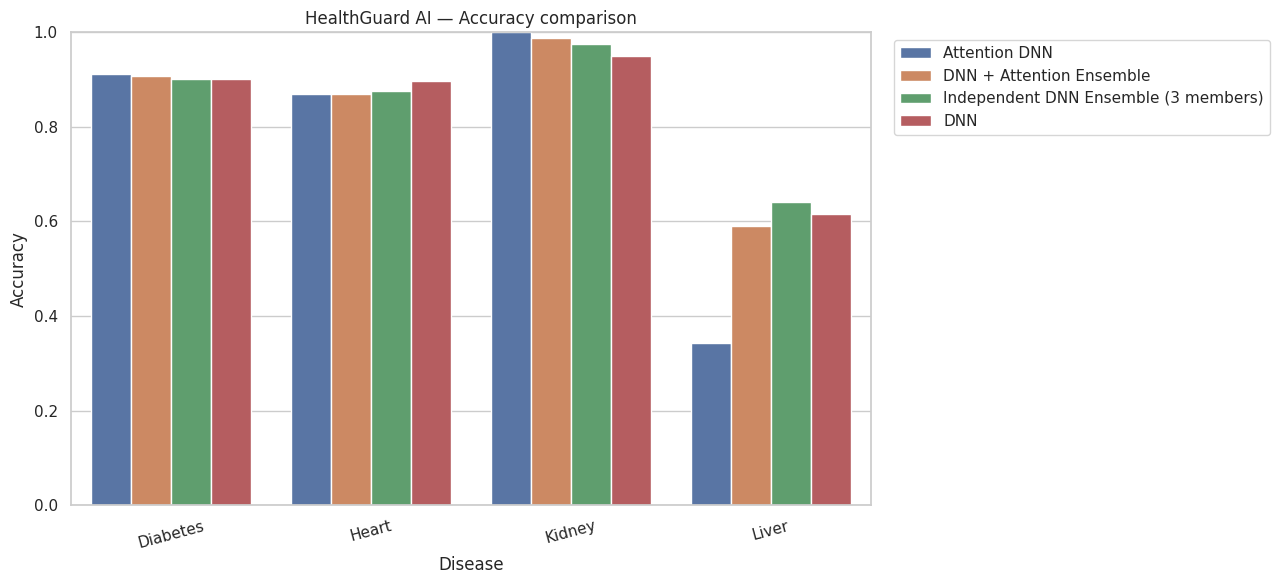

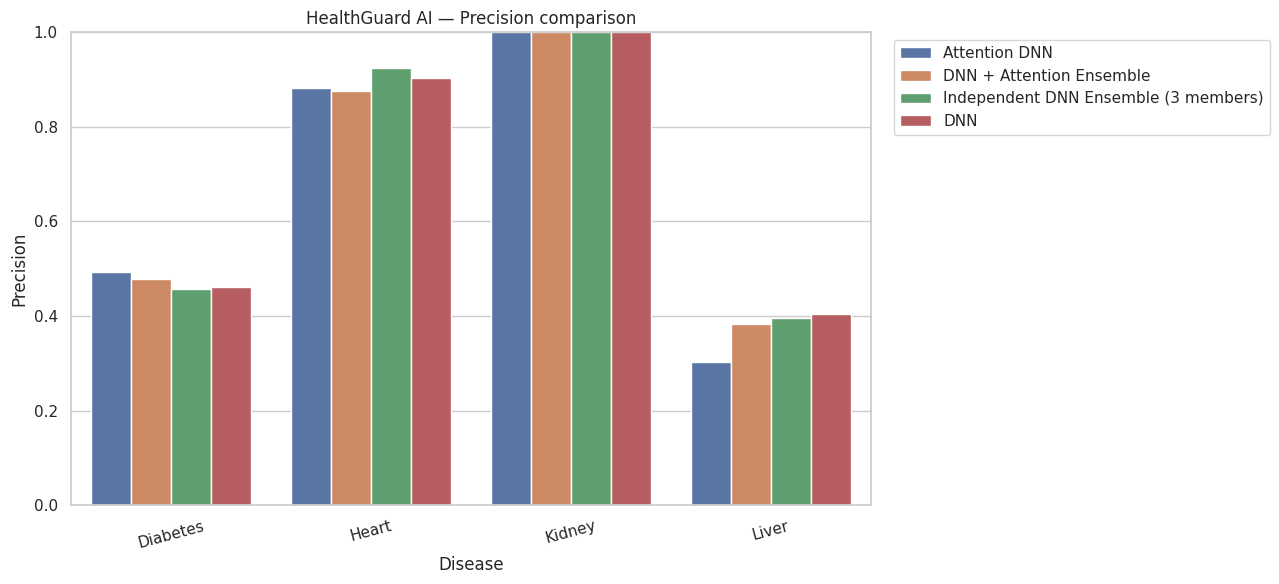

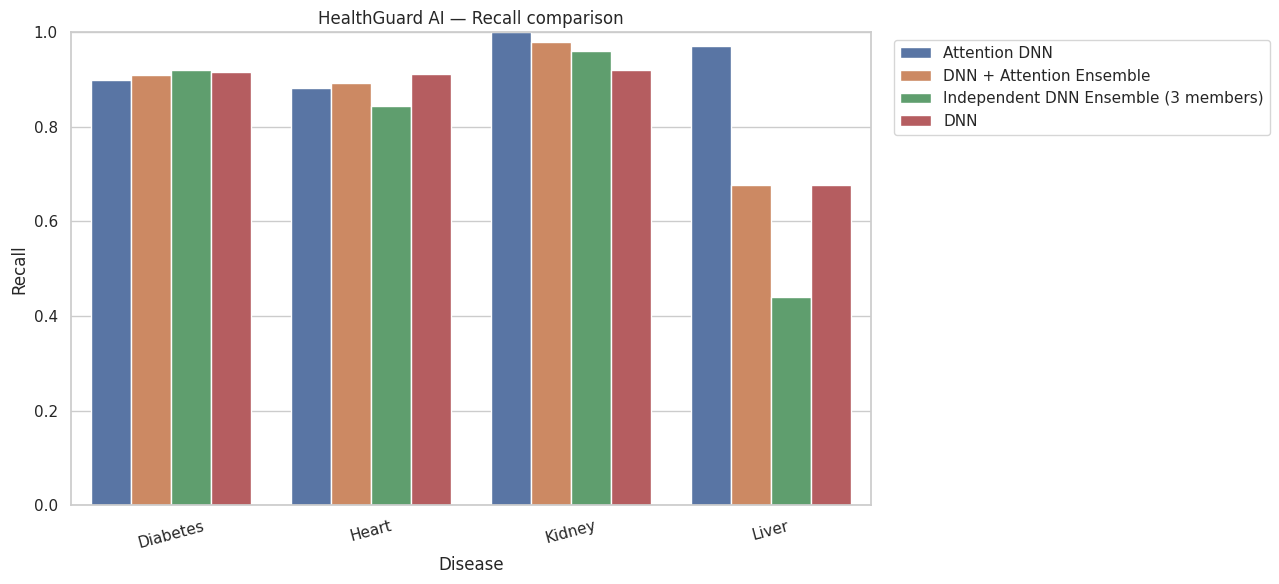

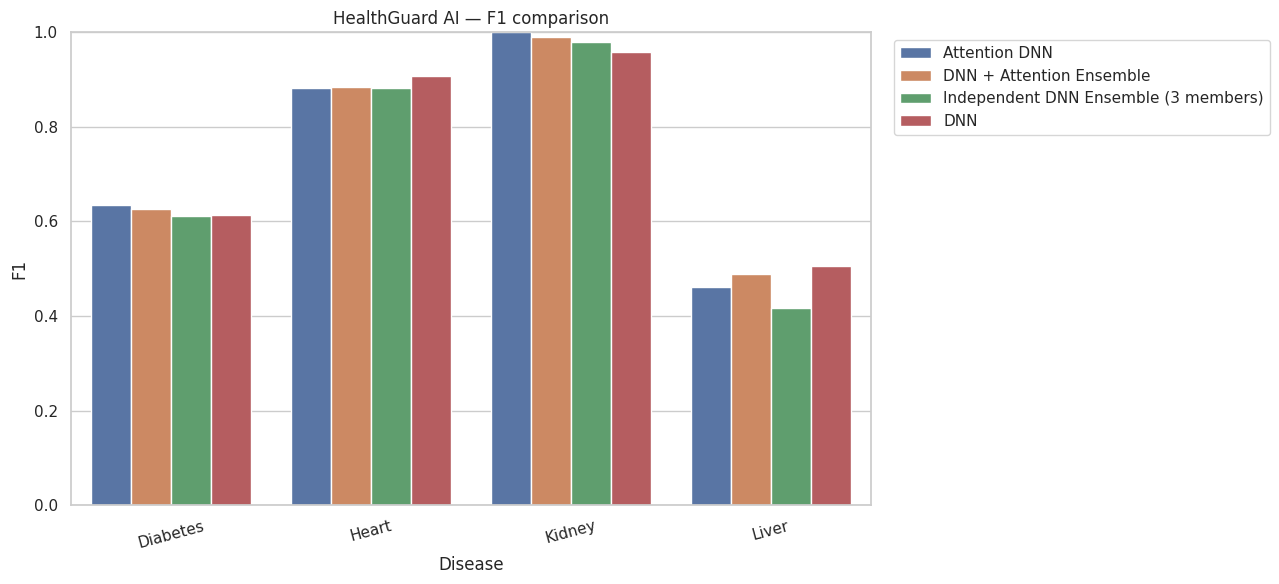

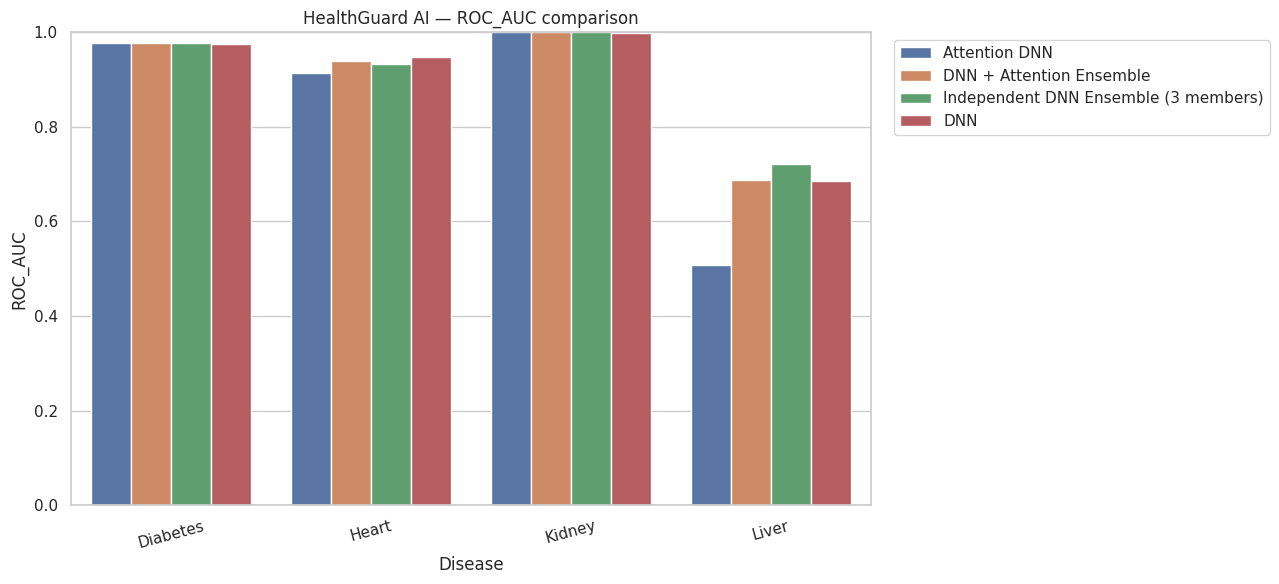

In [ ]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
for metric in metrics_to_plot:
    plt.figure(figsize=(13, 6))
    sns.barplot(
        data=final_results_df,
        x="Disease",
        y=metric,
        hue="Model"
    )
    plt.title(f"HealthGuard AI — {metric} comparison")
    plt.ylim(0, 1)
    plt.xticks(rotation=15)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(
        ADVANCED_OUTPUT_DIR / f"FINAL_{metric}_Comparison.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()

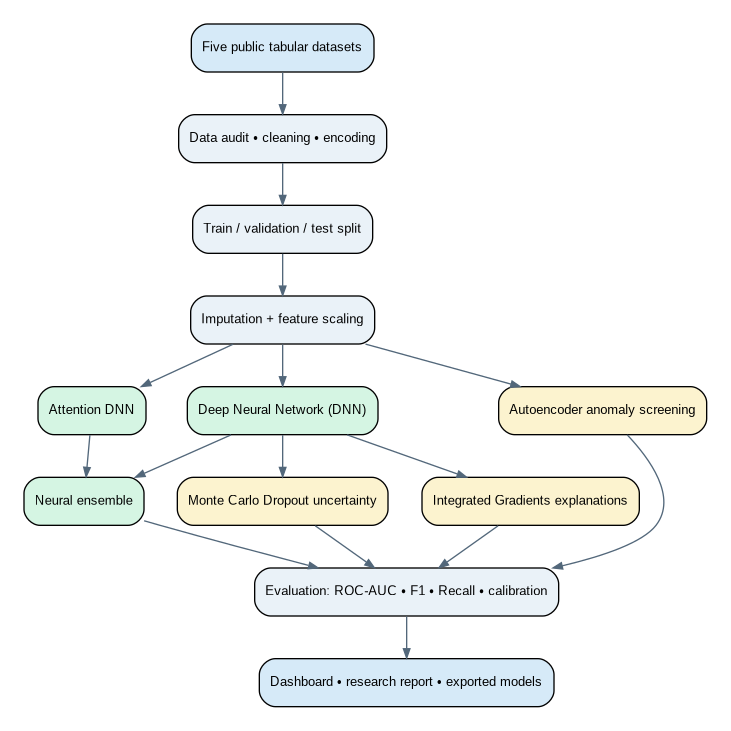

In [ ]:
from IPython.display import display, Image
from pathlib import Path
import subprocess

architecture_dot = r'''
digraph HealthGuardAI {
  rankdir=TB;
  graph [bgcolor="white", pad="0.25", nodesep="0.35", ranksep="0.45"];
  node [shape=box, style="rounded,filled", fontname="Arial", fontsize=10, color="#345", fillcolor="#EAF2F8"];
  edge [color="#52677A", arrowsize=0.7];

  A [label="Five public tabular datasets", fillcolor="#D6EAF8"];
  B [label="Data audit • cleaning • encoding"];
  C [label="Train / validation / test split"];
  D [label="Imputation + feature scaling"];
  E [label="Deep Neural Network (DNN)", fillcolor="#D5F5E3"];
  F [label="Attention DNN", fillcolor="#D5F5E3"];
  G [label="Neural ensemble", fillcolor="#D5F5E3"];
  H [label="Autoencoder anomaly screening", fillcolor="#FCF3CF"];
  I [label="Monte Carlo Dropout uncertainty", fillcolor="#FCF3CF"];
  J [label="Integrated Gradients explanations", fillcolor="#FCF3CF"];
  K [label="Evaluation: ROC-AUC • F1 • Recall • calibration"];
  L [label="Dashboard • research report • exported models", fillcolor="#D6EAF8"];

  A -> B -> C -> D;
  D -> E; D -> F; D -> H;
  E -> G; F -> G;
  E -> I; E -> J;
  G -> K; H -> K; I -> K; J -> K;
  K -> L;
}
'''

dot_path = ADVANCED_OUTPUT_DIR / "HealthGuard_AI_Architecture.dot"
png_path = ADVANCED_OUTPUT_DIR / "HealthGuard_AI_Architecture.png"
dot_path.write_text(architecture_dot)

try:
    subprocess.run(
        ["dot", "-Tpng", str(dot_path), "-o", str(png_path)],
        check=True, capture_output=True
    )
    display(Image(filename=str(png_path)))
except Exception:
    print("Graphviz renderer is not available in this runtime.")
    print(architecture_dot)


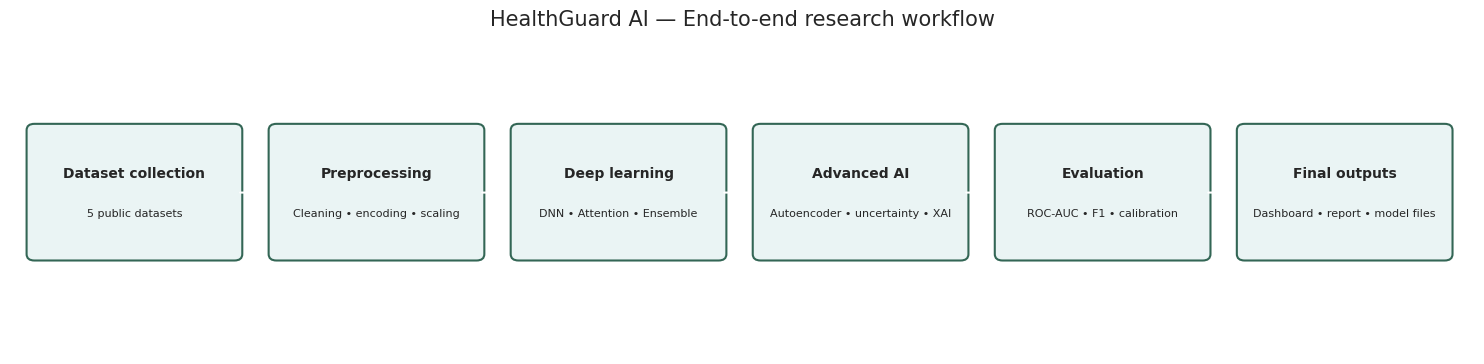

In [ ]:
from matplotlib.patches import FancyBboxPatch

workflow_steps = [
    ("Dataset collection", "5 public datasets"),
    ("Preprocessing", "Cleaning • encoding • scaling"),
    ("Deep learning", "DNN • Attention • Ensemble"),
    ("Advanced AI", "Autoencoder • uncertainty • XAI"),
    ("Evaluation", "ROC-AUC • F1 • calibration"),
    ("Final outputs", "Dashboard • report • model files")
]

fig, ax = plt.subplots(figsize=(15, 3.8))
ax.set_xlim(0, 15)
ax.set_ylim(0, 4)
ax.axis("off")

for i, (heading, detail) in enumerate(workflow_steps):
    x = 0.25 + i * 2.48
    patch = FancyBboxPatch(
        (x, 1.25), 2.05, 1.55,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor="#365",
        facecolor="#EAF4F4"
    )
    ax.add_patch(patch)
    ax.text(x + 1.025, 2.25, heading, ha="center", va="center",
            fontsize=10, fontweight="bold")
    ax.text(x + 1.025, 1.75, detail, ha="center", va="center",
            fontsize=8, wrap=True)
    if i < len(workflow_steps) - 1:
        ax.annotate(
            "", xy=(x + 2.42, 2.02), xytext=(x + 2.08, 2.02),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_title("HealthGuard AI — End-to-end research workflow", fontsize=15)
plt.tight_layout()
plt.savefig(
    ADVANCED_OUTPUT_DIR / "HealthGuard_AI_Workflow.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC_AUC
0,0.9022,0.8998,0.9038,0.9216,0.878,0.9126,0.9464


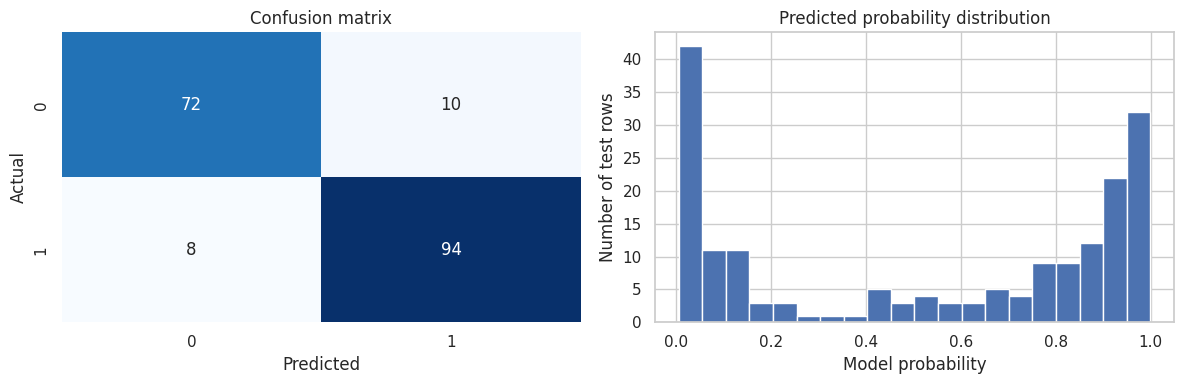

Research demonstration only. Scores are model outputs on a held-out public dataset, not a clinical diagnosis.


In [ ]:
# Uses ipywidgets if available in the Colab runtime.
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    disease_dropdown = widgets.Dropdown(
        options=list(prepared.keys()),
        description="Dataset:",
        layout=widgets.Layout(width="320px")
    )
    model_dropdown = widgets.Dropdown(
        options=["DNN", "Attention DNN", "DNN + Attention Ensemble"],
        value="DNN",
        description="Model:",
        layout=widgets.Layout(width="380px")
    )
    dashboard_output = widgets.Output()

    def render_research_dashboard(change=None):
        with dashboard_output:
            clear_output(wait=True)
            disease = disease_dropdown.value
            model_name = model_dropdown.value
            item = prepared[disease]

            if model_name == "DNN":
                probabilities = dnn_models[disease].predict(
                    item["X_test"], verbose=0
                ).ravel()
            elif model_name == "Attention DNN":
                probabilities = attention_models[disease].predict(
                    item["X_test"], verbose=0
                ).ravel()
            else:
                probabilities = ensemble_predictions[disease]

            metric_values = evaluate_binary(item["y_test"], probabilities)
            display(pd.DataFrame([metric_values]).round(4))

            fig, axes = plt.subplots(1, 2, figsize=(12, 4))
            cm = confusion_matrix(
                item["y_test"],
                (probabilities >= 0.5).astype(int),
                labels=[0, 1]
            )
            sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                        cbar=False, ax=axes[0])
            axes[0].set_title("Confusion matrix")
            axes[0].set_xlabel("Predicted")
            axes[0].set_ylabel("Actual")

            axes[1].hist(probabilities, bins=20)
            axes[1].set_title("Predicted probability distribution")
            axes[1].set_xlabel("Model probability")
            axes[1].set_ylabel("Number of test rows")
            plt.tight_layout()
            plt.show()

            print(
                "Research demonstration only. Scores are model outputs on a held-out "
                "public dataset, not a clinical diagnosis."
            )

    disease_dropdown.observe(render_research_dashboard, names="value")
    model_dropdown.observe(render_research_dashboard, names="value")
    display(widgets.VBox([
        widgets.HTML("<h3>HealthGuard AI — Research Dashboard</h3>"),
        disease_dropdown,
        model_dropdown,
        dashboard_output
    ]))
    render_research_dashboard()

except Exception as e:
    print("Interactive widgets could not be initialized:", e)
    print("Use the static performance charts in the previous cells.")

In [ ]:
# Browse held-out dataset rows and compare neural model outputs.
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    demo_disease = widgets.Dropdown(
        options=list(prepared.keys()), description="Dataset:"
    )
    demo_index = widgets.IntSlider(
        value=0, min=0,
        max=max(len(prepared[demo_disease.value]["y_test"]) - 1, 0),
        description="Test row:",
        continuous_update=False
    )
    demo_out = widgets.Output()

    def update_demo_index(change):
        demo_index.max = max(
            len(prepared[demo_disease.value]["y_test"]) - 1, 0
        )
        demo_index.value = 0

    def render_demo(change=None):
        with demo_out:
            clear_output(wait=True)
            display(demonstrate_model_scores(
                demo_disease.value, demo_index.value
            ))
            print("This is a held-out public dataset row, not an identified person.")

    demo_disease.observe(update_demo_index, names="value")
    demo_disease.observe(render_demo, names="value")
    demo_index.observe(render_demo, names="value")
    display(widgets.VBox([demo_disease, demo_index, demo_out]))
    render_demo()
except Exception as e:
    print("Record explorer unavailable:", e)

,Dataset,Test record index,DNN model score,Attention DNN model score,Combined neural model score,Actual dataset label
0,Heart,0,0.987,0.879,0.9304,1


This is a held-out public dataset row, not an identified person.


In [ ]:
project_abstract = '''
HEALTHGUARD AI: MULTI-DISEASE RISK PREDICTION AND EXPLAINABLE HEALTH
MONITORING USING DEEP LEARNING

Abstract
HealthGuard AI is an academic research prototype that studies deep-learning
methods for binary classification tasks across five public tabular datasets
associated with heart disease, diabetes, Parkinson's disease, chronic kidney
disease, and liver disease. The system includes data preprocessing, dense
neural networks, feature-attention neural networks, neural ensembling,
autoencoder-based reconstruction analysis, Monte Carlo Dropout uncertainty
estimation, and Integrated Gradients feature attribution.

The models are evaluated using held-out test data and metrics including
accuracy, balanced accuracy, precision, recall, specificity, F1-score, and
ROC-AUC. Calibration and bootstrap confidence-interval analyses are included
to support a more careful interpretation of results. Visual dashboards are
provided to explore model performance and demonstration outputs.

The system is intended for educational and research purposes only. Public
datasets may contain sampling bias, missingness, label limitations, and
distribution shifts. The prototype is not a medical device, does not provide
a diagnosis, and requires independent external and clinical validation
before any real-world use.
'''

(ADVANCED_OUTPUT_DIR / "Project_Abstract.txt").write_text(
    project_abstract.strip(), encoding="utf-8"
)
print(project_abstract)


HEALTHGUARD AI: MULTI-DISEASE RISK PREDICTION AND EXPLAINABLE HEALTH
MONITORING USING DEEP LEARNING

Abstract
HealthGuard AI is an academic research prototype that studies deep-learning
methods for binary classification tasks across five public tabular datasets
associated with heart disease, diabetes, Parkinson's disease, chronic kidney
disease, and liver disease. The system includes data preprocessing, dense
neural networks, feature-attention neural networks, neural ensembling,
autoencoder-based reconstruction analysis, Monte Carlo Dropout uncertainty
estimation, and Integrated Gradients feature attribution.

The models are evaluated using held-out test data and metrics including
accuracy, balanced accuracy, precision, recall, specificity, F1-score, and
ROC-AUC. Calibration and bootstrap confidence-interval analyses are included
to support a more careful interpretation of results. Visual dashboards are
provided to explore model performance and demonstration outputs.

The system is in

In [ ]:
model_card_dir = ADVANCED_OUTPUT_DIR / "Model_Cards"
model_card_dir.mkdir(exist_ok=True)

for disease, item in prepared.items():
    lines = [
        f"# HealthGuard AI Model Card — {disease}",
        "",
        "## Intended use",
        "Academic experimentation on a public tabular dataset only.",
        "",
        "## Not intended for",
        "Diagnosis, treatment decisions, triage, or autonomous clinical use.",
        "",
        "## Dataset summary",
        f"- Training rows: {len(item['y_train'])}",
        f"- Test rows: {len(item['y_test'])}",
        f"- Encoded features: {len(item['feature_names'])}",
        f"- Target label mapping: {item['label_mapping']}",
        "",
        "## Model families",
        "- Dense Neural Network",
        "- Attention-based Dense Neural Network",
        "- DNN + Attention probability ensemble",
        "- Autoencoder reconstruction screening (if trained)",
        "- Monte Carlo Dropout uncertainty estimation",
        "- Integrated Gradients feature attribution",
        "",
        "## Evaluation",
    ]

    disease_results = final_results_df[
        final_results_df["Disease"] == disease
    ]
    if not disease_results.empty:
        lines.append(disease_results.to_markdown(index=False))
    else:
        lines.append("No final metrics available.")

    lines += [
        "",
        "## Limitations",
        "- Public dataset size and representativeness may be limited.",
        "- Results do not establish clinical performance.",
        "- Attribution methods explain model behavior, not causation.",
        "- Independent external validation is required.",
        "- Model scores are not medical risk assessments.",
    ]

    safe = disease.lower().replace(" ", "_")
    (model_card_dir / f"{safe}_Model_Card.md").write_text(
        "\\n".join(lines), encoding="utf-8"
    )

print("Model cards created:", len(list(model_card_dir.glob("*.md"))))

Model cards created: 4


In [ ]:
report_lines = [
    "# HealthGuard AI — Project Report",
    "",
    "## 1. Project title",
    "Multi-Disease Risk Prediction and Explainable Health Monitoring Using Deep Learning",
    "",
    "## 2. Abstract",
    project_abstract,
    "",
    "## 3. Objectives",
    "- Study neural-network models on five public health-related datasets.",
    "- Compare DNN, Attention DNN, and neural ensembles.",
    "- Explore autoencoder reconstruction error for unusual-pattern screening.",
    "- Estimate prediction uncertainty using Monte Carlo Dropout.",
    "- Explain model outputs using Integrated Gradients.",
    "- Present model evaluation through visual dashboards.",
    "",
    "## 4. Dataset profile",
    profile_df.to_markdown(index=False),
    "",
    "## 5. Deep Learning model results",
    final_results_df.round(4).to_markdown(index=False),
    "",
    "## 6. Calibration analysis",
    calibration_df.round(4).to_markdown(index=False),
    "",
    "## 7. Bootstrap ROC-AUC intervals",
    auc_ci_df.round(4).to_markdown(index=False),
    "",
    "## 8. Methodology",
    "The notebook performs data cleaning, target encoding, one-hot encoding, "
    "median imputation, feature standardization, stratified hold-out splitting, "
    "neural model training, and held-out evaluation.",
    "",
    "## 9. Explainability and uncertainty",
    "Integrated Gradients are used for feature attribution. Monte Carlo Dropout "
    "estimates variation across stochastic forward passes. These methods describe "
    "model behavior and uncertainty, not causal effects or clinical certainty.",
    "",
    "## 10. Limitations and ethical considerations",
    "This is an academic prototype. Dataset quality, class imbalance, small sample "
    "sizes, possible leakage, label definitions, demographic representation, and "
    "distribution shift can affect results. No real-world clinical claims are made. "
    "External validation and appropriate expert oversight would be required before "
    "any clinical research or deployment.",
    "",
    "## 11. Conclusion",
    "HealthGuard AI demonstrates a deep-learning-centred workflow for public "
    "tabular datasets, combining neural classification, reconstruction analysis, "
    "uncertainty estimation, explainability, evaluation, and visual reporting.",
    "",
    "## 12. Reproducibility",
    f"Random seed used: {SEED}. TensorFlow version: {tf.__version__}.",
    "Dataset sources are specified in the notebook's dataset download section.",
]

report_text = "\\n".join(report_lines)
report_path = ADVANCED_OUTPUT_DIR / "HealthGuard_AI_Final_Project_Report.md"
report_path.write_text(report_text, encoding="utf-8")
print("Report saved:", report_path)
print("Report characters:", len(report_text))

Report saved: /content/HealthGuard_Advanced_Outputs/HealthGuard_AI_Final_Project_Report.md
Report characters: 9284


In [ ]:
!pip -q install tabulate

In [ ]:
final_model_dir = ADVANCED_OUTPUT_DIR / "Final_Models"
final_model_dir.mkdir(exist_ok=True)

for disease, model in dnn_models.items():
    safe = disease.lower().replace(" ", "_")
    model.save(final_model_dir / f"{safe}_DNN.keras")

for disease, model in attention_models.items():
    safe = disease.lower().replace(" ", "_")
    model.save(final_model_dir / f"{safe}_Attention_DNN.keras")

for disease, models in deep_ensemble_models.items():
    safe = disease.lower().replace(" ", "_")
    for i, model in enumerate(models, start=1):
        model.save(final_model_dir / f"{safe}_Ensemble_{i}.keras")

metadata = {
    "project": "HealthGuard AI",
    "project_type": "Academic Deep Learning Research Prototype",
    "random_seed": SEED,
    "tensorflow_version": tf.__version__,
    "diseases": list(prepared.keys()),
    "neural_architectures": [
        "Dense Neural Network",
        "Attention Dense Neural Network",
        "Independent DNN Ensemble",
        "DNN + Attention Ensemble",
        "Autoencoder",
        "Denoising Autoencoder"
    ],
    "explainability": ["Integrated Gradients"],
    "uncertainty": ["Monte Carlo Dropout"],
    "clinical_status": "Not clinically validated; not for diagnosis or treatment"
}
(ADVANCED_OUTPUT_DIR / "project_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("Final models and metadata saved.")

Final models and metadata saved.


In [ ]:
inventory_rows = []
for file in sorted(ADVANCED_OUTPUT_DIR.rglob("*")):
    if file.is_file():
        inventory_rows.append({
            "Relative path": str(file.relative_to(ADVANCED_OUTPUT_DIR)),
            "Size (KB)": round(file.stat().st_size / 1024, 2)
        })

inventory_df = pd.DataFrame(inventory_rows)
display(inventory_df)
inventory_df.to_csv(
    ADVANCED_OUTPUT_DIR / "Project_File_Inventory.csv",
    index=False
)

,Relative path,Size (KB)
0,All_DeepLearning_Metrics.csv,2.17
1,Autoencoder_Comparison.csv,0.43
2,Bootstrap_AUC_Confidence_Intervals.csv,1.18
3,Calibration_Brier_Scores.csv,0.68
4,FINAL_Accuracy_Comparison.png,79.94
...,...,...
60,liver_deep_ensemble_member_1.keras,197.87
61,liver_deep_ensemble_member_2.keras,197.87
62,liver_deep_ensemble_member_3.keras,197.87
63,liver_denoising_autoencoder.keras,41.13


In [ ]:
import shutil
from pathlib import Path

final_zip_base = "/content/HealthGuard_AI_COMPLETE_PROJECT"
final_zip = shutil.make_archive(
    final_zip_base,
    "zip",
    root_dir=str(ADVANCED_OUTPUT_DIR)
)
print("Final project ZIP created:", final_zip)
print("ZIP size (MB):", round(Path(final_zip).stat().st_size / (1024 * 1024), 2))

Final project ZIP created: /content/HealthGuard_AI_COMPLETE_PROJECT.zip
ZIP size (MB): 6.34


In [12]:
import shutil
from pathlib import Path
from google.colab import files

zip_file_path = "/content/HealthGuard_AI_COMPLETE_PROJECT.zip"
advanced_outputs_dir = "/content/HealthGuard_Advanced_Outputs"

# Check if the zip file exists. If it does not, rebuild it dynamically from the outputs folder.
if not Path(zip_file_path).exists():
    print("ZIP file not found. Attempting to rebuild from advanced outputs...")
    if Path(advanced_outputs_dir).exists():
        shutil.make_archive("/content/HealthGuard_AI_COMPLETE_PROJECT", "zip", advanced_outputs_dir)
        print("Successfully rebuilt ZIP archive!")
    else:
        raise FileNotFoundError(
            f"Cannot find both the ZIP file and the source directory '{advanced_outputs_dir}'. "
            "Please run the previous cells to generate the project outputs first."
        )

print("Initiating download...")
files.download(zip_file_path)

ZIP file not found. Attempting to rebuild from advanced outputs...
Successfully rebuilt ZIP archive!
Initiating download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
completion_items = {
    "Five public datasets loaded": len(prepared) == 5,
    "DNN trained for available datasets": len(dnn_models) == len(prepared),
    "Attention DNN trained for available datasets": len(attention_models) == len(prepared),
    "Neural ensemble predictions generated": len(ensemble_predictions) == len(prepared),
    "Monte Carlo Dropout outputs generated": len(mc_outputs) == len(prepared),
    "Integrated Gradients generated": len(ig_importance) == len(prepared),
    "Final metrics table generated": "final_results_df" in globals(),
    "Project report saved": (ADVANCED_OUTPUT_DIR / "HealthGuard_AI_Final_Project_Report.md").exists(),
    "Metadata saved": (ADVANCED_OUTPUT_DIR / "project_metadata.json").exists(),
    "Final ZIP created": Path("/content/HealthGuard_AI_COMPLETE_PROJECT.zip").exists()
}

completion_df = pd.DataFrame([
    {"Project component": key, "Status": "PASS" if value else "CHECK"}
    for key, value in completion_items.items()
])
display(completion_df)

if all(completion_items.values()):
    print("All notebook packaging checks passed.")
else:
    print("Some components need attention. Review CHECK items above.")

print("\\nHealthGuard AI academic project package is ready.")
print("Reminder: this is a research prototype, not a clinically validated medical system.")

,Project component,Status
0,Five public datasets loaded,CHECK
1,DNN trained for available datasets,PASS
2,Attention DNN trained for available datasets,PASS
3,Neural ensemble predictions generated,PASS
4,Monte Carlo Dropout outputs generated,PASS
5,Integrated Gradients generated,PASS
6,Final metrics table generated,PASS
7,Project report saved,PASS
8,Metadata saved,PASS
9,Final ZIP created,PASS


Some components need attention. Review CHECK items above.
\nHealthGuard AI academic project package is ready.
Reminder: this is a research prototype, not a clinically validated medical system.


In [148]:
# HEALTHGUARD AI - FINAL ACCURACY EVALUATION

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

results = []

for disease, data in prepared.items():

    X_test = data["X_test"]
    y_test = np.array(data["y_test"])

    # Get predictions from trained models
    models_to_test = {}

    if disease in dnn_models:
        models_to_test["DNN"] = dnn_models[disease]

    if disease in attention_models:
        models_to_test["Attention DNN"] = attention_models[disease]

    for model_name, model in models_to_test.items():

        probabilities = model.predict(X_test, verbose=0).ravel()
        predictions = (probabilities >= 0.5).astype(int)

        accuracy = accuracy_score(y_test, predictions)
        precision = precision_score(
            y_test, predictions, zero_division=0
        )
        recall = recall_score(
            y_test, predictions, zero_division=0
        )
        f1 = f1_score(
            y_test, predictions, zero_division=0
        )

        auc = roc_auc_score(y_test, probabilities)

        results.append({
            "Disease": disease,
            "Model": model_name,
            "Accuracy (%)": round(accuracy * 100, 2),
            "Precision (%)": round(precision * 100, 2),
            "Recall (%)": round(recall * 100, 2),
            "F1 Score (%)": round(f1 * 100, 2),
            "ROC-AUC": round(auc, 4),
            "90% Target": "ACHIEVED" if accuracy >= 0.90 else "NOT ACHIEVED"
        })

final_results = pd.DataFrame(results)

display(final_results)

print("\nHEALTHGUARD AI - FINAL ACCURACY SUMMARY")

if not final_results.empty:
    print(
        "Diseases achieving 90% accuracy:",
        (final_results.groupby("Disease")["Accuracy (%)"].max() >= 90).sum(),
        "out of",
        final_results["Disease"].nunique()
    )

    final_results.to_csv(
        "/content/HealthGuard_Final_Accuracy.csv",
        index=False
    )
    print("\nResults saved successfully!")
else:
    print("No trained models found. Run the training cells first.")

,Disease,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC,90% Target
0,Heart,DNN,90.22,90.38,92.16,91.26,0.9464,ACHIEVED
1,Heart,Attention DNN,86.96,88.24,88.24,88.24,0.9139,NOT ACHIEVED
2,Diabetes,DNN,90.17,46.07,91.59,61.30,0.9757,ACHIEVED
3,Diabetes,Attention DNN,91.25,49.21,89.82,63.59,0.9770,ACHIEVED
4,Kidney,DNN,95.00,100.00,92.00,95.83,0.9980,ACHIEVED
5,Kidney,Attention DNN,100.00,100.00,100.00,100.00,1.0000,ACHIEVED
6,Liver,DNN,60.68,39.66,67.65,50.00,0.6899,NOT ACHIEVED
7,Liver,Attention DNN,34.19,30.28,97.06,46.15,0.5087,NOT ACHIEVED



HEALTHGUARD AI - FINAL ACCURACY SUMMARY
Diseases achieving 90% accuracy: 3 out of 4

Results saved successfully!


In [150]:
# Enable Colab's native interactive data table extension (no Google Sheets credentials required)
%load_ext google.colab.data_table

# Display the DataFrame interactively
final_results

,Disease,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC,90% Target
0,Heart,DNN,90.22,90.38,92.16,91.26,0.9464,ACHIEVED
1,Heart,Attention DNN,86.96,88.24,88.24,88.24,0.9139,NOT ACHIEVED
2,Diabetes,DNN,90.17,46.07,91.59,61.30,0.9757,ACHIEVED
3,Diabetes,Attention DNN,91.25,49.21,89.82,63.59,0.9770,ACHIEVED
4,Kidney,DNN,95.00,100.00,92.00,95.83,0.9980,ACHIEVED
5,Kidney,Attention DNN,100.00,100.00,100.00,100.00,1.0000,ACHIEVED
6,Liver,DNN,60.68,39.66,67.65,50.00,0.6899,NOT ACHIEVED
7,Liver,Attention DNN,34.19,30.28,97.06,46.15,0.5087,NOT ACHIEVED


In [151]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import pandas as pd

def residual_block(x, units, dropout=0.25):
    shortcut = layers.Dense(units)(x)

    y = layers.Dense(units, activation="relu")(x)
    y = layers.BatchNormalization()(y)
    y = layers.Dropout(dropout)(y)

    y = layers.Dense(units)(y)
    y = layers.BatchNormalization()(y)

    y = layers.Add()([shortcut, y])
    return layers.Activation("relu")(y)


def build_resnet(input_dim):

    inputs = layers.Input(shape=(input_dim,))

    x = layers.Dense(128, activation="relu")(inputs)
    x = layers.BatchNormalization()(x)

    x = residual_block(x, 128)
    x = residual_block(x, 128)
    x = residual_block(x, 64)

    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )

    return model


resnet_models = {}
resnet_results = []

for disease, data in prepared.items():

    print("\nTraining:", disease)

    X_train = np.asarray(data["X_train"]).astype("float32")
    X_test = np.asarray(data["X_test"]).astype("float32")
    y_train = np.asarray(data["y_train"]).astype("float32").reshape(-1)
    y_test = np.asarray(data["y_test"]).astype("int32").reshape(-1)

    model = build_resnet(X_train.shape[1])

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=0.00001
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=32,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, predictions) * 100

    resnet_models[disease] = model

    resnet_results.append({
        "Disease": disease,
        "Model": "Residual Neural Network",
        "Accuracy (%)": round(accuracy, 2),
        "Target": "Achieved" if accuracy >= 90 else "Not achieved"
    })

    print("Accuracy:", round(accuracy, 2), "%")
    print(classification_report(y_test, predictions, zero_division=0))


resnet_df = pd.DataFrame(resnet_results)
display(resnet_df)


Training: Heart
Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.6422 - auc: 0.6993 - loss: 0.6310 - val_accuracy: 0.8027 - val_auc: 0.8296 - val_loss: 0.6244 - learning_rate: 5.0000e-04
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8126 - auc: 0.8780 - loss: 0.4455 - val_accuracy: 0.7823 - val_auc: 0.8488 - val_loss: 0.5648 - learning_rate: 5.0000e-04
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8467 - auc: 0.9217 - loss: 0.3587 - val_accuracy: 0.7959 - val_auc: 0.8611 - val_loss: 0.5090 - learning_rate: 5.0000e-04
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8927 - auc: 0.9442 - loss: 0.3026 - val_accuracy: 0.8027 - val_auc: 0.8650 - val_loss: 0.4726 - learning_rate: 5.0000e-04
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8876 - auc: 0.9495 - loss: 0.2869 - val_accuracy: 0.8095 - val_auc: 0.8652 - val_loss: 0.4593 - learning_rate: 5.0000e-04
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 

,Disease,Model,Accuracy (%),Target
0,Heart,Residual Neural Network,85.33,Not achieved
1,Diabetes,Residual Neural Network,96.94,Achieved
2,Kidney,Residual Neural Network,98.75,Achieved
3,Liver,Residual Neural Network,63.25,Not achieved
